# Multifractality, temporal dependence and cooperativity in 50 assets
### Consolidated, reproducible notebook for the *Finance Research Letters* submission

**What this notebook does (one run, top to bottom):**

| § | Content | Replaces / extends |
|---|---------|--------------------|
| 0 | Reproducibility layer: fixed config, seeds, pinned versions, hashed data cache, run metadata | hard-coded `D:\...` paths, un-frozen `END` dates |
| 1 | Data (50 assets 2010–2026, 15-stock DJIA cohort + S&P 500 2003–2026, DJIA/Nasdaq 1990–2024) | all three data scripts |
| 2 | **Vectorised MF-DFA** (verified against your original loop implementation) | `mfdfa` in `dfa_and_its_variants` |
| 3 | **Three-surrogate decomposition of Δα**: shuffle / IAAFT / phase-randomised → fat-tail, linear-correlation and nonlinear-dependence shares | extends the shuffle-only test |
| 4 | Cross-section: Δα by asset class, OLS with robust SEs, half-sample stability, robustness grid | new |
| 5 | **Rolling Δα vs rolling pairwise correlation** across 2008, 2020, 2022; vol-controlled, circular-shift significance | extends the slide |
| 6 | Correlation build-up with proper statistics: block-bootstrap CIs, HAC slope, placebo ranking, heat-maps | fixes the slide |
| 7 | √t scaling → **variance-ratio test** (fixes the mis-labelled "Ratio" column) | `correlation_and_returns` |
| 8 | Paper-numbers JSON, `requirements.txt`, run metadata | new |

**Deliberately excluded:** drawdown (as requested), LPPL fits (all windows flagged "artefact", parameters pinned to bounds) and the Rosenstein-LLE sweep (the lag 7–10 "bump" is inside the ±0.03 noise band). Both are better as future work than as claims.

**Interpretation note.** The shuffle surrogate removes *all* temporal dependence, which includes volatility clustering (a nonlinear dependence), not just linear correlation. Raw-return autocorrelation is ≈0, so most of the former "correlation-driven share" is really *nonlinear* dependence. §3 separates the two; word the paper accordingly.

**How to run.** `pip install -r requirements.txt` (written by §8) → Run All. First run downloads and freezes data into `flr_run/data_cache/` with SHA-256 hashes; later runs reuse the cache and refuse to run if a file was altered. Set `FORCE_REDOWNLOAD=True` only to deliberately refresh.

In [26]:
# ═════════════════════════════ §0  SETUP & REPRODUCIBILITY ═════════════════════════════
import os, sys, json, hashlib, platform, time, zlib, warnings
from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import savgol_filter
from scipy.special import logsumexp
from scipy.stats import false_discovery_control
from joblib import Parallel, delayed
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ── Every tunable lives here. Nothing below hard-codes a path, date or seed. ──
CFG = dict(
    SEED            = 42,
    DATA_MODE       = os.environ.get("FLR_DATA_MODE", "yfinance"),  # "synthetic" = smoke-test ONLY
    FORCE_REDOWNLOAD= False,
    # data windows (END dates are FIXED so reruns see identical samples)
    START_A="2010-01-01", END_A="2026-04-11",     # 50-asset MF-DFA universe
    START_B="2003-01-01", END_B="2026-04-11",     # DJIA cohort + S&P 500 (episodes)
    START_C="1990-01-01", END_C="2024-01-01",     # DJIA / Nasdaq (scaling law)
    # MF-DFA (identical to your original settings)
    Q_VALS=[float(q) for q in range(-30, 31, 5)],
    SCALE_MIN=20, SCALE_MAX=800, N_SCALES=30, POLY_ORD=1, OVERLAP=0.75,
    # surrogates (paper run: 500, as in your original)
    N_SURR=int(os.environ.get("FLR_N_SURR", 500)), IAAFT_ITERS=50, N_JOBS=-1,
    # rolling analysis
    ROLL_WINDOW=1000, ROLL_STEP=20, ROLL_Q=[float(q) for q in range(-10, 11, 2)],
    ROLL_SCALE_MIN=10, ROLL_SCALE_MAX=250, ROLL_N_SCALES=20,
    CORR_WINDOW=60, N_BOOT=int(os.environ.get("FLR_N_BOOT", 1000)), BOOT_BLOCK=5,
    N_PERM=int(os.environ.get("FLR_N_PERM", 2000)),
)
CFG_HASH = hashlib.sha256(json.dumps(CFG, sort_keys=True).encode()).hexdigest()[:10]

SYN = CFG["DATA_MODE"] == "synthetic"
BASE   = Path(os.environ.get("FLR_OUT", "flr_run_SYNTHETIC" if SYN else "flr_run"))
CACHE  = BASE / ("data_synthetic" if SYN else "data_cache")
FIGS, TABLES = BASE / "figures", BASE / "tables"
for d in (CACHE, FIGS, TABLES): d.mkdir(parents=True, exist_ok=True)

np.random.seed(CFG["SEED"])                     # legacy global RNG (nothing here relies on it)
ROOT_SS = np.random.SeedSequence(CFG["SEED"])   # every random task gets a spawned child → order-independent
def rng_for(name):
    """Deterministic RNG per named task, independent of execution order / n_jobs."""
    return np.random.default_rng(np.random.SeedSequence([CFG["SEED"], zlib.crc32(name.encode())]))

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
CLASS_COLORS = {"Tech": "#1f77b4", "Financials": "#17becf", "Health/Cons": "#bcbd22", "Energy/Ind": "#8c564b",
                "Commodity": "#ff7f0e", "Crypto": "#9467bd", "Intl ETF": "#2ca02c"}
GROUP_ORDER = list(CLASS_COLORS)          # fixed plotting / table order

TIMINGS = {}
@contextmanager
def timed(name):
    t0 = time.time(); yield
    TIMINGS[name] = round(time.time() - t0, 1); print(f"[{name}] {TIMINGS[name]} s")

def savefig(fig, name):
    fig.savefig(FIGS / name, bbox_inches="tight"); plt.show()

def savetable(df, name, **kw):
    df.to_csv(TABLES / name, **kw); return df

if SYN:
    print("█" * 78 + "\n█  SYNTHETIC SMOKE-TEST MODE — numbers are meaningless, do NOT use in the paper  █\n" + "█" * 78)
print(f"run config hash {CFG_HASH} | python {platform.python_version()} | output → {BASE.resolve()}")

run config hash 0aaa4807ab | python 3.9.19 | output → /Users/hridayshah/StockParticle/StockParticle/scripts/notebooks/flr_run


In [27]:
# ═════════════════════════════ §1  DATA LAYER (cache + SHA-256 manifest) ═════════════════════════════
MANIFEST = CACHE / "manifest.json"

def _sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""): h.update(chunk)
    return h.hexdigest()

def _manifest():
    return json.loads(MANIFEST.read_text()) if MANIFEST.exists() else {}

# ---- synthetic generator (smoke tests only; never used unless DATA_MODE == "synthetic") ----
_MASTER = pd.bdate_range("1985-01-01", "2026-12-31")
_SYN_START = {"ETH-USD": "2017-11-09", "META": "2012-05-18"}
def _ar_vol(rng, n, phi=0.98, s=0.15):
    lv = np.zeros(n); e = rng.standard_normal(n)
    for i in range(1, n): lv[i] = phi * lv[i - 1] + s * e[i]
    return np.exp(lv)
_FACTOR = None
def _synth(ticker, start, end):
    global _FACTOR
    if _FACTOR is None:
        r = np.random.default_rng(CFG["SEED"])
        _FACTOR = pd.Series(0.008 * _ar_vol(r, len(_MASTER)) * r.standard_t(4, len(_MASTER)) / np.sqrt(2), index=_MASTER)
    r = np.random.default_rng(CFG["SEED"] + zlib.crc32(ticker.encode()))
    crypto = ticker.endswith("-USD")
    s0 = max(pd.Timestamp(start), pd.Timestamp(_SYN_START.get(ticker, start)))
    idx = pd.date_range(s0, pd.Timestamp(end) - pd.Timedelta(days=1), freq="D" if crypto else "B")
    fac = _FACTOR.reindex(idx).fillna(0.0).values
    idio = 0.010 * _ar_vol(r, len(idx)) * r.standard_t(4, len(idx)) / np.sqrt(2)
    return pd.Series(100 * np.exp(np.cumsum(0.5 * fac + idio)), index=idx, name="Close")

def _download_yf(ticker, start, end):
    import yfinance as yf
    for _ in range(3):
        df = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=True, threads=False)
        if df is not None and len(df): break
        time.sleep(2)
    else:
        raise RuntimeError(f"yfinance returned nothing for {ticker}")
    s = df["Close"].squeeze().dropna()
    s.name = "Close"; return s

def _read_cached(fn, ticker):
    return pd.read_csv(fn, index_col=0, parse_dates=True, float_precision="round_trip").iloc[:, 0].rename(ticker)

def get_close(ticker, start, end):
    fn = CACHE / f"{ticker.replace('^','IDX_').replace('=','_')}_{start}_{end}.csv"
    man = _manifest()
    if fn.exists() and not CFG["FORCE_REDOWNLOAD"]:
        if fn.name in man and man[fn.name]["sha256"] != _sha256(fn):
            raise RuntimeError(f"{fn.name}: cached file does not match its recorded SHA-256 — data was modified.")
        return _read_cached(fn, ticker)
    s = _synth(ticker, start, end) if SYN else _download_yf(ticker, start, end)
    s.to_csv(fn, header=["Close"])
    man[fn.name] = dict(sha256=_sha256(fn), rows=len(s), first=str(s.index[0].date()), last=str(s.index[-1].date()),
                        source="synthetic" if SYN else f"yfinance {metadata.version('yfinance')}",
                        downloaded_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"))
    MANIFEST.write_text(json.dumps(man, indent=1, sort_keys=True))
    return _read_cached(fn, ticker)      # ALWAYS re-read from disk so first run == every later run, bit for bit

def get_panel(tickers, start, end):
    return pd.concat([get_close(t, start, end) for t in tickers], axis=1, sort=False)

# ---- universe (same 50 tickers as your DFA notebook) ----
SECTORS_A = {
    "Tech":        ["AAPL","MSFT","GOOG","AMZN","NVDA","META","TSLA","NFLX","AMD","INTC"],
    "Financials":  ["JPM","BAC","GS","MS","WFC","BLK","C","AXP","V","MA"],
    "Health/Cons": ["JNJ","PFE","UNH","MRK","ABBV","PG","KO","PEP","WMT","COST"],
    "Energy/Ind":  ["XOM","CVX","COP","BA","CAT","GE","HON","LMT","RTX","UPS"],
    "Commodities": ["GC=F","SI=F","CL=F"],
    "Crypto":      ["BTC-USD","ETH-USD"],
    "Intl ETFs":   ["EWJ","EWZ","FXI","EWG","EWU"],
}
TICKERS_A = [t for v in SECTORS_A.values() for t in v]
GROUP = {t: {"Tech": "Tech", "Financials": "Financials", "Health/Cons": "Health/Cons", "Energy/Ind": "Energy/Ind",
             "Commodities": "Commodity", "Crypto": "Crypto", "Intl ETFs": "Intl ETF"}[s]
         for s, v in SECTORS_A.items() for t in v}
COHORT = ["MMM","AXP","BA","CAT","CVX","KO","XOM","GE","IBM","MCD","MRK","PG","WMT","JPM","MSFT"]  # 15 stocks, as on the slide

with timed("data download/load"):
    prices_A = get_panel(TICKERS_A, CFG["START_A"], CFG["END_A"])

returns_A, data_notes = {}, []
for t in TICKERS_A:
    p = prices_A[t].dropna()
    bad = int((p <= 0).sum())
    if bad: data_notes.append(f"{t}: {bad} non-positive price(s) dropped before log (e.g. WTI Apr-2020)")
    p = p[p > 0]
    returns_A[t] = np.log(p).diff().dropna()

summary = pd.DataFrame({t: dict(group=GROUP[t], n_returns=len(r), first=r.index[0].date(), last=r.index[-1].date(),
                                ann_vol=r.std() * np.sqrt(252 if GROUP[t] != "Crypto" else 365))
                        for t, r in returns_A.items()}).T
savetable(summary, "data_summary.csv")
print(summary.head(8).to_string()); print("…"); print("\n".join(data_notes) or "no data issues")

[data download/load] 0.3 s
     group n_returns       first        last   ann_vol
AAPL  Tech      4091  2010-01-05  2026-04-10  0.281027
MSFT  Tech      4091  2010-01-05  2026-04-10  0.256168
GOOG  Tech      4091  2010-01-05  2026-04-10  0.275484
AMZN  Tech      4091  2010-01-05  2026-04-10  0.327581
NVDA  Tech      4091  2010-01-05  2026-04-10  0.452708
META  Tech      3492  2012-05-21  2026-04-10  0.397614
TSLA  Tech      3969  2010-06-30  2026-04-10  0.572423
NFLX  Tech      4091  2010-01-05  2026-04-10  0.492176
…
CL=F: 1 non-positive price(s) dropped before log (e.g. WTI Apr-2020)


In [3]:
# ═════════════════════════════ §2  MF-DFA (vectorised) + verification ═════════════════════════════
_M_CACHE = {}
def _resid_maker(s, poly):
    """M = I − X(XᵀX)⁻¹Xᵀ : residuals of a degree-`poly` least-squares fit on a length-s window."""
    key = (s, poly)
    if key not in _M_CACHE:
        t = np.linspace(-1, 1, s)
        X = np.vander(t, poly + 1)
        _M_CACHE[key] = np.eye(s) - X @ np.linalg.pinv(X)
    return _M_CACHE[key]

def make_scales(N, smin, smax, n_scales, poly):
    smax = min(smax, N // 4); smin = max(smin, poly + 2)
    sc = np.unique(np.logspace(np.log10(smin), np.log10(smax), n_scales).astype(int))
    return sc[sc >= smin]

def mfdfa_fast(x, q, smin, smax, n_scales, poly=1, overlap=0.75):
    """MF-DFA on log-returns x. Same algorithm as the original loop version; detrending done in one matrix product."""
    y = np.cumsum(x - np.mean(x)); N = len(y)
    scales = make_scales(N, smin, smax, n_scales, poly)
    q = np.asarray(q, float)
    Fq = np.full((len(q), len(scales)), np.nan)
    for i, s in enumerate(scales):
        step = max(1, int(s * (1.0 - overlap)))
        starts = np.arange(0, N - s + 1, step)
        if len(starts) < 4: continue
        seg = y[starts[:, None] + np.arange(s)[None, :]]
        res = seg @ _resid_maker(s, poly)
        rms = np.sqrt((res ** 2).mean(axis=1)); rms = rms[rms > 0]
        if len(rms) == 0: continue
        lr = np.log(rms)
        for j, qq in enumerate(q):
            Fq[j, i] = np.exp(lr.mean()) if qq == 0 else np.exp((logsumexp(qq * lr) - np.log(len(lr))) / qq)
    hq = np.full(len(q), np.nan)
    for j in range(len(q)):
        m = np.isfinite(Fq[j]) & (Fq[j] > 0)
        if m.sum() >= 4: hq[j] = np.polyfit(np.log(scales[m]), np.log(Fq[j][m]), 1)[0]
    return scales, Fq, hq

def spectrum(q, hq):
    """tau(q), alpha(q), f(alpha) — Legendre transform with Savitzky–Golay smoothing, as in the original."""
    q = np.asarray(q, float); tau = q * hq - 1.0
    wl = min(5, len(tau) if len(tau) % 2 else len(tau) - 1)
    ts = savgol_filter(tau, wl, 2) if len(tau) >= 5 else tau
    alpha = np.gradient(ts, q); return tau, alpha, q * alpha - ts

def delta_alpha(q, hq):
    if not np.all(np.isfinite(hq)): return np.nan
    a = spectrum(q, hq)[1]; return float(np.ptp(a[np.isfinite(a)]))

def da_of(x, q=None, smin=None, smax=None, ns=None, po=None, ov=None):
    c = CFG
    q = c["Q_VALS"] if q is None else q
    _, _, hq = mfdfa_fast(x, q, smin or c["SCALE_MIN"], smax or c["SCALE_MAX"], ns or c["N_SCALES"],
                          c["POLY_ORD"] if po is None else po, c["OVERLAP"] if ov is None else ov)
    return delta_alpha(q, hq), hq

# ---- verification against the ORIGINAL (slow, np.polyfit) implementation ----
def mfdfa_reference(x, q_vals, scale_min, scale_max, n_scales, poly_ord=1, overlap=0.75):
    y = np.cumsum(x - x.mean()); N = len(y)
    scale_max = min(scale_max, N // 4); scale_min = max(scale_min, poly_ord + 2)
    scales = np.unique(np.logspace(np.log10(scale_min), np.log10(scale_max), n_scales).astype(int))
    scales = scales[scales >= scale_min]
    Fqs = np.full((len(q_vals), len(scales)), np.nan)
    for i, s in enumerate(scales):
        step = max(1, int(s * (1.0 - overlap))); starts = np.arange(0, N - s + 1, step)
        if len(starts) < 4: continue
        t = np.arange(s); rms = []
        for st in starts:
            seg = y[st:st + s]; coef = np.polyfit(t, seg, poly_ord)
            r = np.sqrt(np.mean((seg - np.polyval(coef, t)) ** 2))
            if r > 0: rms.append(r)
        rms = np.asarray(rms)
        for j, q in enumerate(q_vals):
            Fqs[j, i] = np.exp(0.5 * np.mean(np.log(rms ** 2))) if q == 0 else (np.mean(rms ** q)) ** (1.0 / q)
    hq = np.full(len(q_vals), np.nan)
    for j in range(len(q_vals)):
        m = np.isfinite(Fqs[j]) & (Fqs[j] > 0)
        if m.sum() >= 4: hq[j] = np.polyfit(np.log(scales[m]), np.log(Fqs[j][m]), 1)[0]
    return scales, Fqs, hq

_x = returns_A["AAPL"].values[:2500]
_, _, h_ref = mfdfa_reference(_x, CFG["Q_VALS"], CFG["SCALE_MIN"], CFG["SCALE_MAX"], CFG["N_SCALES"])
_, _, h_new = mfdfa_fast(_x, CFG["Q_VALS"], CFG["SCALE_MIN"], CFG["SCALE_MAX"], CFG["N_SCALES"])
print("max |H(q)_fast − H(q)_original| =", np.nanmax(np.abs(h_ref - h_new)))
assert np.allclose(h_ref, h_new, atol=1e-6, equal_nan=True), "vectorised MF-DFA disagrees with the original"
t0 = time.time(); da_of(returns_A["AAPL"].values); print(f"one full-length Δα evaluation: {time.time()-t0:.3f} s")

max |H(q)_fast − H(q)_original| = 3.3306690738754696e-16
one full-length Δα evaluation: 0.204 s


In [4]:
# ═════════════════════════════ §3  SURROGATE DECOMPOSITION OF Δα ═════════════════════════════
# shuffle : destroys ALL temporal dependence, keeps the return distribution (fat tails)
# IAAFT   : keeps distribution AND linear autocorrelation, destroys nonlinear dependence (vol clustering)
# phase   : keeps linear autocorrelation only (Gaussianised), destroys distribution + nonlinear dependence
#   Δα_orig = Δα_shuffle                     (distribution / fat tails)
#           + (Δα_IAAFT − Δα_shuffle)        (linear correlation)
#           + (Δα_orig − Δα_IAAFT)           (nonlinear dependence, e.g. volatility clustering)

def iaaft(x, rng, n_iter=50):
    xs = np.sort(x); amp = np.abs(np.fft.rfft(x)); y = rng.permutation(x); prev = None
    for _ in range(n_iter):
        ph = np.angle(np.fft.rfft(y))
        ys = np.fft.irfft(amp * np.exp(1j * ph), n=len(x))
        ranks = np.argsort(np.argsort(ys)); y = xs[ranks]
        if prev is not None and np.array_equal(ranks, prev): break
        prev = ranks
    return y

def phase_randomise(x, rng):
    F = np.fft.rfft(x - x.mean()); ph = rng.uniform(0, 2 * np.pi, len(F)); ph[0] = 0
    if len(x) % 2 == 0: ph[-1] = 0
    return np.fft.irfft(np.abs(F) * np.exp(1j * ph), n=len(x)) + x.mean()

def surrogate_task(ticker, x, n_surr, iters, cfg):
    """Pure function (picklable, no globals mutated) → deterministic for a given (seed, ticker)."""
    rng = np.random.default_rng(np.random.SeedSequence([cfg["SEED"], zlib.crc32(ticker.encode())]))
    q, smin, smax, ns, po, ov = (cfg[k] for k in ("Q_VALS","SCALE_MIN","SCALE_MAX","N_SCALES","POLY_ORD","OVERLAP"))
    N = len(x)
    def da(z):
        _, _, hq = mfdfa_fast(z, q, smin, smax, ns, po, ov); return delta_alpha(q, hq)
    _, _, h0 = mfdfa_fast(x, q, smin, smax, ns, po, ov)
    d0 = delta_alpha(q, h0); h2 = h0[q.index(2.0)] if 2.0 in q else np.nan
    S = {k: np.full(n_surr, np.nan) for k in ("shuffle", "iaaft", "phase")}
    for i in range(n_surr):
        S["shuffle"][i] = da(rng.permutation(x))
        S["iaaft"][i]   = da(iaaft(x, rng, iters))
        S["phase"][i]   = da(phase_randomise(x, rng))
    row = dict(ticker=ticker, n=N, delta_alpha=d0, H2=h2)
    for k, v in S.items():
        v = v[np.isfinite(v)]
        row[f"{k}_mean"] = v.mean(); row[f"{k}_sd"] = v.std(ddof=1)
        row[f"p_{k}"] = (np.sum(v >= d0) + 1) / (len(v) + 1)       # right-tailed: orig wider than surrogate
    return row

with timed("surrogate decomposition"):
    raw = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(
        delayed(surrogate_task)(t, returns_A[t].values, CFG["N_SURR"], CFG["IAAFT_ITERS"], CFG) for t in TICKERS_A)

res = pd.DataFrame(raw).set_index("ticker").loc[TICKERS_A]
res["group"] = [GROUP[t] for t in res.index]
for k in ("shuffle", "iaaft", "phase"):
    res[f"q_{k}"] = false_discovery_control(res[f"p_{k}"].values, method="bh")      # Benjamini–Hochberg
res["share_fat_tail_pct"]  = 100 * res["shuffle_mean"] / res["delta_alpha"]
res["share_linear_pct"]    = 100 * (res["iaaft_mean"] - res["shuffle_mean"]) / res["delta_alpha"]
res["share_nonlinear_pct"] = 100 * (res["delta_alpha"] - res["iaaft_mean"]) / res["delta_alpha"]
res["share_temporal_pct"]  = 100 * (res["delta_alpha"] - res["shuffle_mean"]) / res["delta_alpha"]   # = your old "corr_share_pct"
savetable(res, "delta_alpha_surrogates.csv")

n = len(res)
print(f"Assets: {n} | surrogates per test: {CFG['N_SURR']}")
for k, lab in (("shuffle", "temporal dependence matters  (orig > shuffle)"),
               ("iaaft",   "nonlinear dependence matters (orig > IAAFT)"),
               ("phase",   "non-Gaussian/nonlinear structure (orig > phase-rand.)")):
    print(f"  BH q<0.05 — {lab:55s}: {(res[f'q_{k}'] < .05).sum():>2d}/{n}")
print("\nMean / median share of Δα (%):")
print(res[["share_fat_tail_pct", "share_linear_pct", "share_nonlinear_pct", "share_temporal_pct"]].agg(["mean", "median"]).round(1).to_string())
print("\nΔα by asset class:"); print(res.groupby("group")["delta_alpha"].agg(["count", "mean", "min", "max"]).round(3).to_string())

[surrogate decomposition] 517.0 s
Assets: 50 | surrogates per test: 500
  BH q<0.05 — temporal dependence matters  (orig > shuffle)          : 36/50
  BH q<0.05 — nonlinear dependence matters (orig > IAAFT)            : 35/50
  BH q<0.05 — non-Gaussian/nonlinear structure (orig > phase-rand.)  : 49/50

Mean / median share of Δα (%):
        share_fat_tail_pct  share_linear_pct  share_nonlinear_pct  share_temporal_pct
mean                  73.0               0.7                 26.3                27.0
median                66.5               2.5                 32.6                33.5

Δα by asset class:
           count   mean    min    max
group                                
Commodity      3  0.569  0.511  0.666
Crypto         2  0.590  0.580  0.600
Equity        40  0.536  0.181  0.824
Intl ETF       5  0.615  0.485  0.681


In [28]:
res["group"] = [GROUP[t] for t in res.index]
if "res_x" in globals(): res_x["group"] = [GROUP[t] for t in res_x.index]

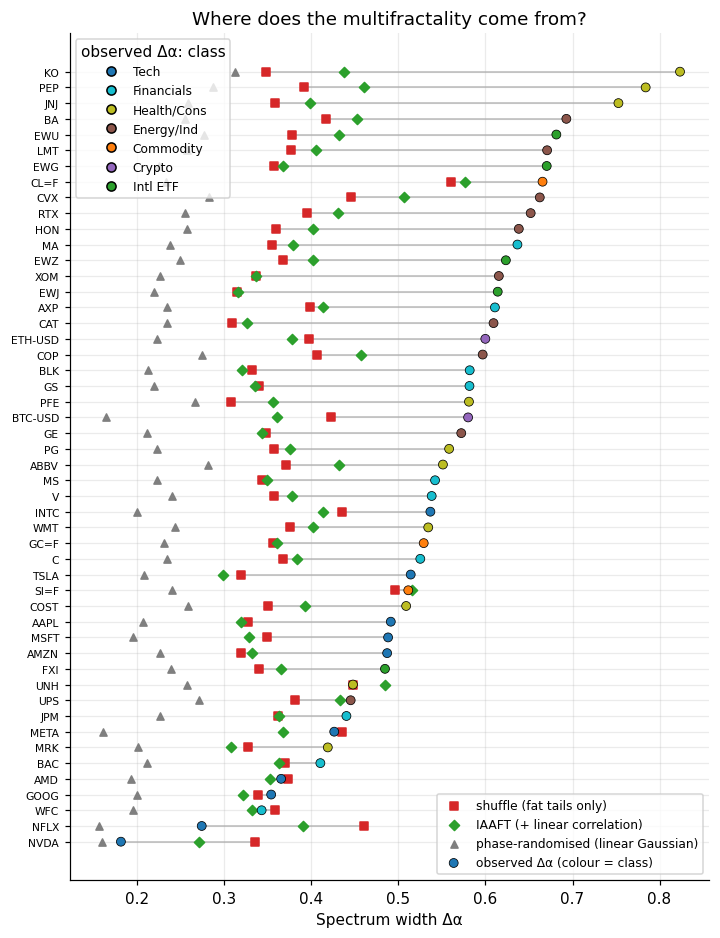

In [29]:
# ── Figure 1: observed Δα vs the three surrogate means (sorted) ──
o = res.sort_values("delta_alpha")
fig, ax = plt.subplots(figsize=(7.5, 10)); y = np.arange(len(o))
ax.hlines(y, o["shuffle_mean"], o["delta_alpha"], color="#bbb", lw=1, zorder=1)
ax.scatter(o["shuffle_mean"], y, s=22, marker="s", c="#d62728", label="shuffle (fat tails only)", zorder=3)
ax.scatter(o["iaaft_mean"],   y, s=22, marker="D", c="#2ca02c", label="IAAFT (+ linear correlation)", zorder=3)
ax.scatter(o["phase_mean"],   y, s=22, marker="^", c="#7f7f7f", label="phase-randomised (linear Gaussian)", zorder=3)
ax.scatter(o["delta_alpha"],  y, s=34, c=[CLASS_COLORS[g] for g in o["group"]], edgecolor="k", lw=.5, label="observed Δα (colour = class)", zorder=4)
ax.set_yticks(y); ax.set_yticklabels(o.index, fontsize=7); ax.set_xlabel("Spectrum width Δα")
from matplotlib.lines import Line2D
leg1 = ax.legend(loc="lower right", fontsize=8, frameon=True); ax.add_artist(leg1)
h2 = [Line2D([], [], marker="o", ls="", mfc=c, mec="k", label=g) for g, c in CLASS_COLORS.items()]
ax.legend(handles=h2, loc="upper left", fontsize=8, title="observed Δα: class", frameon=True)
ax.set_title("Where does the multifractality come from?")
savefig(fig, "fig1_surrogate_decomposition.png")

                                                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------
Intercept                                      0.1078      0.134      0.807      0.420      -0.154       0.370
C(group, Treatment('Tech'))[T.Commodity]       0.2853      0.125      2.284      0.022       0.040       0.530
C(group, Treatment('Tech'))[T.Crypto]          0.3279      0.084      3.885      0.000       0.163       0.493
C(group, Treatment('Tech'))[T.Energy/Ind]      0.1260      0.053      2.377      0.017       0.022       0.230
C(group, Treatment('Tech'))[T.Financials]     -0.0075      0.067     -0.112      0.911      -0.139       0.124
C(group, Treatment('Tech'))[T.Health/Cons]     0.1472      0.066      2.225      0.026       0.018       0.277
C(group, Treatment('Tech'))[T.Intl ETF]        0.0798      0.068      1.169      0.242      -0.054       0.213
l

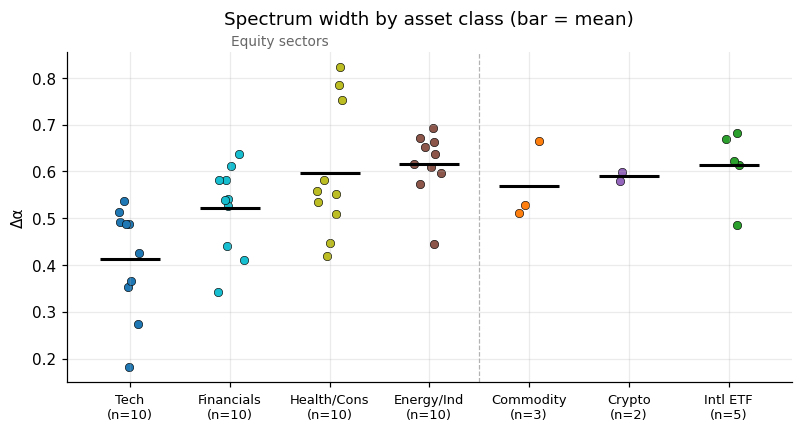


Half-sample stability of Δα: Spearman ρ = 0.09 (p = 0.54); mean |Δ| = 0.168


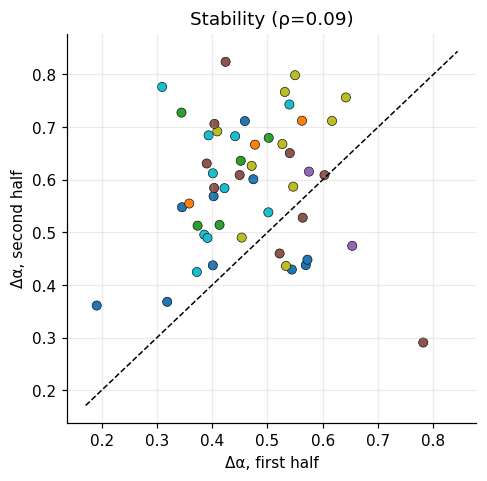

[robustness grid] 11.8 s

Robustness of Δα across MF-DFA specifications:
               spearman_vs_baseline  mean_delta_alpha  mean_abs_change
baseline                      1.000             0.548            0.000
q in [-10,10]                 0.990             0.558            0.028
q in [-20,20]                 0.994             0.605            0.057
scale_max=400                 0.874             0.582            0.048
scale_min=10                  0.882             0.589            0.052
poly order 2                  0.864             0.541            0.042
overlap 0.5                   0.968             0.543            0.024


,spearman_vs_baseline,mean_delta_alpha,mean_abs_change
baseline,1.000000,0.548076,0.000000
"q in [-10,10]",0.989628,0.558123,0.028237
"q in [-20,20]",0.994430,0.605208,0.057131
scale_max=400,0.874094,0.581661,0.048294
scale_min=10,0.882353,0.589466,0.052440
poly order 2,0.863529,0.541032,0.041660
overlap 0.5,0.968403,0.542618,0.023822


In [30]:
# ═════════════════════════════ §4  CROSS-SECTION, STABILITY, ROBUSTNESS ═════════════════════════════
# --- 4a. Δα by asset class + OLS with heteroskedasticity-robust (HC3) SEs ---
R_all = pd.concat(returns_A, axis=1, sort=False)
corr_mat = R_all.corr(min_periods=250)                       # pairwise-complete (crypto trades weekends)
avg_corr = (corr_mat.sum() - 1) / (corr_mat.notna().sum() - 1)      # mean correlation with the other assets
reg = res[["delta_alpha", "H2", "group"]].copy()
reg["log_vol"]  = np.log(summary["ann_vol"].astype(float))
reg["avg_corr"] = avg_corr
fit = smf.ols("delta_alpha ~ C(group, Treatment('Tech')) + log_vol + avg_corr", data=reg).fit(cov_type="HC3")
print(fit.summary().tables[1]); print(f"N={int(fit.nobs)}  R²={fit.rsquared:.3f}  (HC3 robust SEs; small N → treat as descriptive)")
savetable(pd.DataFrame({"coef": fit.params, "se": fit.bse, "p": fit.pvalues}), "ols_delta_alpha.csv")

fig, ax = plt.subplots(figsize=(8.5, 3.9)); rng_j = rng_for("jitter")
for i, g in enumerate(GROUP_ORDER):
    d = reg[reg["group"] == g]
    ax.scatter(i + rng_j.uniform(-.15, .15, len(d)), d["delta_alpha"], c=CLASS_COLORS[g], edgecolor="k", lw=.4, s=30)
    ax.hlines(d["delta_alpha"].mean(), i - .3, i + .3, color="k", lw=2)
ax.axvline(3.5, color="0.7", lw=.8, ls="--")
ax.text(1.5, 1.01, "Equity sectors", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=9, color="0.4")
ax.set_xticks(range(len(GROUP_ORDER)))
ax.set_xticklabels([f"{g}\n(n={(reg['group'] == g).sum()})" for g in GROUP_ORDER], fontsize=8.5); ax.set_ylabel("Δα")
ax.set_title("Spectrum width by asset class (bar = mean)", pad=18); savefig(fig, "fig2_delta_alpha_by_class.png")

# --- 4b. Half-sample stability (no resampling bias, unlike a block bootstrap) ---
h1, h2 = {}, {}
for t in TICKERS_A:
    x = returns_A[t].values; m = len(x) // 2
    h1[t], h2[t] = da_of(x[:m])[0], da_of(x[m:])[0]
stab = pd.DataFrame({"first_half": h1, "second_half": h2}); stab["group"] = [GROUP[t] for t in stab.index]
rho, p_rho = stats.spearmanr(stab["first_half"], stab["second_half"], nan_policy="omit")
print(f"\nHalf-sample stability of Δα: Spearman ρ = {rho:.2f} (p = {p_rho:.3g}); mean |Δ| = {np.nanmean(np.abs(stab.first_half-stab.second_half)):.3f}")
savetable(stab, "delta_alpha_half_sample.csv")
fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.scatter(stab["first_half"], stab["second_half"], c=[CLASS_COLORS[g] for g in stab["group"]], edgecolor="k", lw=.4)
lim = [np.nanmin(stab[["first_half","second_half"]].values) - .02, np.nanmax(stab[["first_half","second_half"]].values) + .02]
ax.plot(lim, lim, "k--", lw=1); ax.set_xlabel("Δα, first half"); ax.set_ylabel("Δα, second half"); ax.set_title(f"Stability (ρ={rho:.2f})")
savefig(fig, "fig3_half_sample_stability.png")

# --- 4c. Robustness grid: does the cross-sectional ranking survive different MF-DFA settings? ---
SPECS = {
    "baseline":        {},
    "q in [-10,10]":   dict(q=list(np.arange(-10, 10.1, 2.5))),
    "q in [-20,20]":   dict(q=list(np.arange(-20, 20.1, 5.0))),
    "scale_max=400":   dict(smax=400),
    "scale_min=10":    dict(smin=10),
    "poly order 2":    dict(po=2),
    "overlap 0.5":     dict(ov=0.5),
}
with timed("robustness grid"):
    grid = pd.DataFrame({name: {t: da_of(returns_A[t].values, **kw)[0] for t in TICKERS_A} for name, kw in SPECS.items()})
rob = pd.DataFrame({name: dict(spearman_vs_baseline=stats.spearmanr(grid["baseline"], grid[name], nan_policy="omit")[0],
                               mean_delta_alpha=grid[name].mean(),
                               mean_abs_change=(grid[name] - grid["baseline"]).abs().mean()) for name in SPECS}).T
print("\nRobustness of Δα across MF-DFA specifications:"); print(rob.round(3).to_string())
savetable(grid, "delta_alpha_robustness_grid.csv"); savetable(rob, "delta_alpha_robustness_summary.csv")

[load episode data] 0.1 s
[rolling MF-DFA] 2.4 s

Rolling Δα (1000d window) vs 60d mean pairwise corr — 243 overlapping windows
  Spearman ρ (raw)                = -0.118  circular-shift p = 0.881
  Spearman ρ (controlling for vol) = +0.119  circular-shift p = 0.884
  (corr vs vol: ρ = +0.71 — why the control matters, cf. Forbes & Rigobon 2002)
  NB: windows overlap heavily → ordinary p-values would be invalid; the circular-shift null keeps autocorrelation.


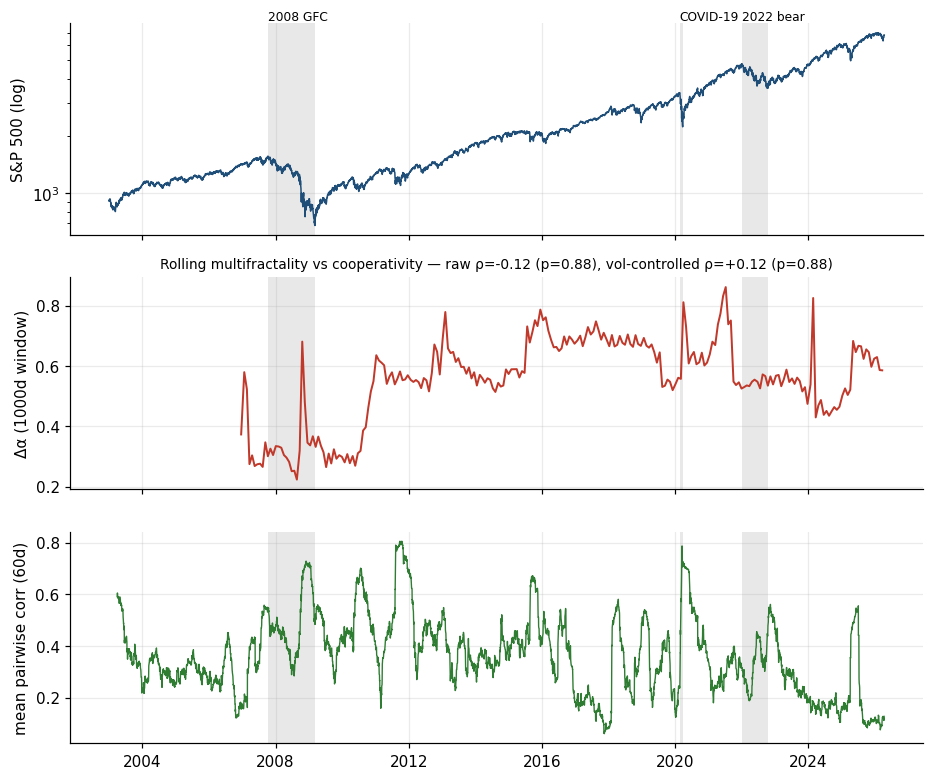

In [7]:
# ═════════════════════════════ §5  ROLLING Δα vs ROLLING PAIRWISE CORRELATION ═════════════════════════════
with timed("load episode data"):
    px_B  = get_panel(COHORT + ["^GSPC"], CFG["START_B"], CFG["END_B"]).dropna()
rB    = np.log(px_B).diff().dropna()
R15   = rB[COHORT]; sp   = rB["^GSPC"]
W, WC = CFG["CORR_WINDOW"], CFG["CORR_WINDOW"]

def mean_pairwise_corr(X):
    c = np.corrcoef(np.asarray(X).T); return c[np.triu_indices(c.shape[0], 1)].mean()

corr60 = pd.Series([mean_pairwise_corr(R15.values[i - WC:i]) for i in range(WC, len(R15) + 1)],
                   index=R15.index[WC - 1:], name="avg_pairwise_corr")
vol60  = (sp.rolling(WC).std() * np.sqrt(252)).rename("vol60")

with timed("rolling MF-DFA"):
    q_r = CFG["ROLL_Q"]; rows = []
    for end in range(CFG["ROLL_WINDOW"], len(sp) + 1, CFG["ROLL_STEP"]):
        d, hq = da_of(sp.values[end - CFG["ROLL_WINDOW"]:end], q=q_r, smin=CFG["ROLL_SCALE_MIN"], smax=CFG["ROLL_SCALE_MAX"], ns=CFG["ROLL_N_SCALES"])
        rows.append((sp.index[end - 1], d, hq[q_r.index(2.0)]))
roll = pd.DataFrame(rows, columns=["date", "delta_alpha", "H2"]).set_index("date")
roll["corr60"] = corr60.reindex(roll.index); roll["vol60"] = vol60.reindex(roll.index)
roll = roll.dropna(); savetable(roll, "rolling_delta_alpha_corr.csv")

# --- association tests: rank correlation, vol-controlled partial, circular-shift null (respects autocorrelation) ---
def _rk(a): return stats.rankdata(a)
def _resid(y, x): X = np.column_stack([np.ones_like(x), x]); return y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
def circ_shift_test(a, b, n_perm, rng):
    ra, rb = _rk(a), _rk(b); obs = np.corrcoef(ra, rb)[0, 1]
    lo = len(a) // 10; ks = rng.integers(lo, len(a) - lo, n_perm)
    null = np.array([np.corrcoef(ra, np.roll(rb, k))[0, 1] for k in ks])
    return obs, (np.sum(np.abs(null) >= abs(obs)) + 1) / (n_perm + 1)

ra, rc, rv = _rk(roll.delta_alpha.values), _rk(roll.corr60.values), _rk(roll.vol60.values)
raw_rho, raw_p = circ_shift_test(roll.delta_alpha.values, roll.corr60.values, CFG["N_PERM"], rng_for("circ_raw"))
pa, pc = _resid(ra, rv), _resid(rc, rv)
par_rho = np.corrcoef(pa, pc)[0, 1]
lo = len(pa) // 10; ks = rng_for("circ_partial").integers(lo, len(pa) - lo, CFG["N_PERM"])
par_p = (np.sum(np.abs([np.corrcoef(pa, np.roll(pc, k))[0, 1] for k in ks]) >= abs(par_rho)) + 1) / (CFG["N_PERM"] + 1)
vol_rho = np.corrcoef(rv, rc)[0, 1]
print(f"\nRolling Δα ({CFG['ROLL_WINDOW']}d window) vs {WC}d mean pairwise corr — {len(roll)} overlapping windows")
print(f"  Spearman ρ (raw)                = {raw_rho:+.3f}  circular-shift p = {raw_p:.3f}")
print(f"  Spearman ρ (controlling for vol) = {par_rho:+.3f}  circular-shift p = {par_p:.3f}")
print(f"  (corr vs vol: ρ = {vol_rho:+.2f} — why the control matters, cf. Forbes & Rigobon 2002)")
print("  NB: windows overlap heavily → ordinary p-values would be invalid; the circular-shift null keeps autocorrelation.")

EPISODES = [("2007-10-09", "2009-03-09", "2008 GFC"), ("2020-02-19", "2020-03-23", "COVID-19"), ("2022-01-03", "2022-10-12", "2022 bear")]
fig, axs = plt.subplots(3, 1, figsize=(10, 8.5), sharex=True)
axs[0].plot(px_B["^GSPC"], c="#1f4e79", lw=1); axs[0].set_yscale("log"); axs[0].set_ylabel("S&P 500 (log)")
axs[1].plot(roll.delta_alpha, c="#c0392b", lw=1.3); axs[1].set_ylabel(f"Δα ({CFG['ROLL_WINDOW']}d window)")
axs[2].plot(corr60, c="#2e7d32", lw=.9); axs[2].set_ylabel(f"mean pairwise corr ({WC}d)")
for a in axs:
    for s, e, lab in EPISODES: a.axvspan(pd.Timestamp(s), pd.Timestamp(e), color="#999", alpha=.22, lw=0)
for s, e, lab in EPISODES: axs[0].text(pd.Timestamp(s), axs[0].get_ylim()[1], lab, fontsize=8, va="bottom")
axs[1].set_title(f"Rolling multifractality vs cooperativity — raw ρ={raw_rho:+.2f} (p={raw_p:.2f}), vol-controlled ρ={par_rho:+.2f} (p={par_p:.2f})", fontsize=9)
savefig(fig, "fig4_rolling_episodes.png")

60-day mean pairwise correlation, 15 DJIA stocks, circular block bootstrap (block=5, B=1000):
                           window_end  mean_corr  ci_lo  ci_hi   Δ vs previous (95% CI)
snapshot                                                                               
Pre-bubble (Jan 2006)      2006-01-31      0.230  0.146  0.318                      NaN
Pre-crash peak (Oct 2007)  2007-10-09      0.535  0.437  0.621  +0.308 [+0.175, +0.438]
During crash (Oct 2008)    2008-10-10      0.576  0.452  0.675  +0.037 [-0.112, +0.179]

Build-up slope (2006-01 → 2007-10): +0.1146/yr  95% HAC CI [+0.0304, +0.1988]   (slide reported +0.0735/yr, no CI)
Placebo: slope exceeds 87% of all 445-day windows (n=535) → NOT unusual build-up

Reconciliation: max of 60d rolling mean corr in Sep-2008…Jun-2009 = 0.729 on 2008-12-01 (slide text says 0.72, heat-map says 0.461 — make the paper use ONE definition)


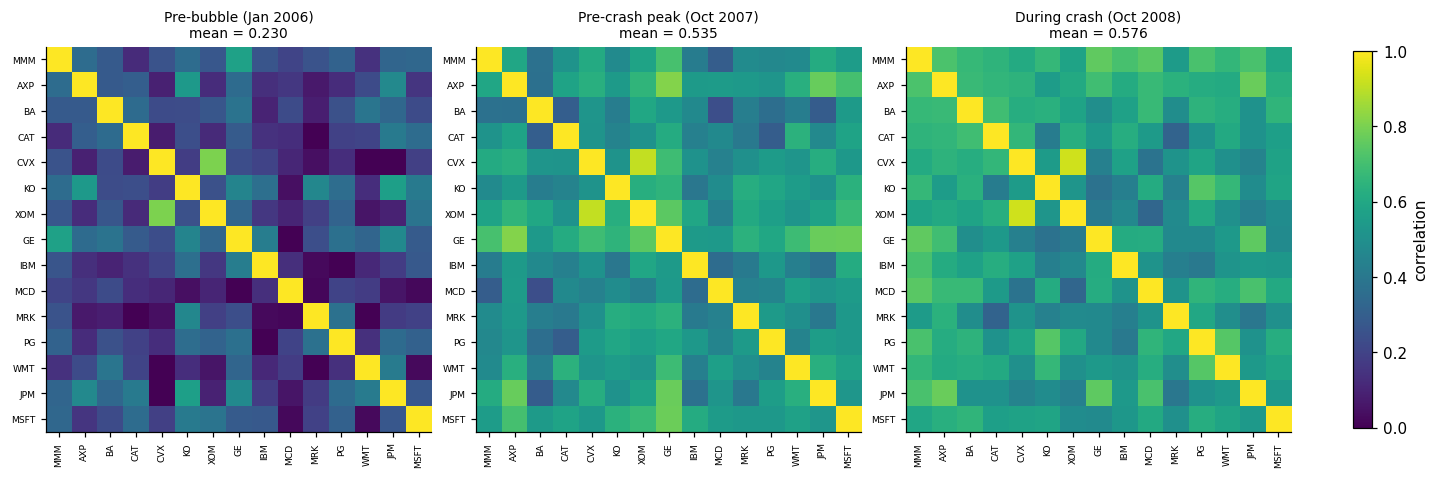

In [8]:
# ═════════════════════════════ §6  CORRELATION BUILD-UP — with proper statistics ═════════════════════════════
def snap_window(date, w=WC):
    i = R15.index.searchsorted(pd.Timestamp(date), side="right"); return R15.iloc[i - w:i]

def boot_mean_corr(win, B, block, rng):
    X = win.values; n = len(X); nb = int(np.ceil(n / block)); out = np.empty(B)
    for b in range(B):
        idx = ((rng.integers(0, n, nb)[:, None] + np.arange(block)) % n).ravel()[:n]
        out[b] = mean_pairwise_corr(X[idx])
    return out

SNAPS = {"Pre-bubble (Jan 2006)": "2006-01-31", "Pre-crash peak (Oct 2007)": "2007-10-09", "During crash (Oct 2008)": "2008-10-10"}
boots, rows = {}, []
for lab, d in SNAPS.items():
    win = snap_window(d); bs = boot_mean_corr(win, CFG["N_BOOT"], CFG["BOOT_BLOCK"], rng_for("boot_" + lab)); boots[lab] = bs
    rows.append(dict(snapshot=lab, window_end=str(win.index[-1].date()), mean_corr=mean_pairwise_corr(win),
                     ci_lo=np.percentile(bs, 2.5), ci_hi=np.percentile(bs, 97.5)))
snap = pd.DataFrame(rows).set_index("snapshot")
labs = list(SNAPS)
for a, b in ((labs[0], labs[1]), (labs[1], labs[2])):
    d = boots[b] - boots[a]; snap.loc[b, f"Δ vs previous (95% CI)"] = f"{d.mean():+.3f} [{np.percentile(d,2.5):+.3f}, {np.percentile(d,97.5):+.3f}]"
print(f"{WC}-day mean pairwise correlation, {len(COHORT)} DJIA stocks, circular block bootstrap (block={CFG['BOOT_BLOCK']}, B={CFG['N_BOOT']}):")
print(snap.round(3).to_string()); savetable(snap, "correlation_snapshots.csv")

# build-up trend with HAC (Newey–West) SEs — rolling series is heavily autocorrelated
seg = corr60["2006-01-01":"2007-10-09"]; tyr = (seg.index - seg.index[0]).days.values / 365.25
ols = sm.OLS(seg.values, sm.add_constant(tyr)).fit(cov_type="HAC", cov_kwds=dict(maxlags=WC))
slope, (lo_s, hi_s) = ols.params[1], ols.conf_int()[1]
print(f"\nBuild-up slope (2006-01 → 2007-10): {slope:+.4f}/yr  95% HAC CI [{lo_s:+.4f}, {hi_s:+.4f}]   (slide reported +0.0735/yr, no CI)")

# placebo: where does that slope rank among ALL equally long windows in 2003-2026?
L = len(seg); sl_all = np.array([np.polyfit(np.arange(L) / 252, corr60.values[i:i + L], 1)[0] for i in range(0, len(corr60) - L, 10)])
pct = 100 * (sl_all < slope).mean()
print(f"Placebo: slope exceeds {pct:.0f}% of all {L}-day windows (n={len(sl_all)}) → {'unusual' if pct > 90 else 'NOT unusual'} build-up")

# reconcile with the slide: which number is the 'crash peak' of the rolling series?
cr = corr60["2008-09-01":"2009-06-30"]
print(f"\nReconciliation: max of {WC}d rolling mean corr in Sep-2008…Jun-2009 = {cr.max():.3f} on {cr.idxmax().date()} "
      f"(slide text says 0.72, heat-map says 0.461 — make the paper use ONE definition)")
fig, axs = plt.subplots(1, 3, figsize=(13, 4.4), constrained_layout=True)
for ax, (lab, d) in zip(axs, SNAPS.items()):
    win = snap_window(d); Cm = np.corrcoef(win.values.T)
    im = ax.imshow(Cm, vmin=0, vmax=1, cmap="viridis"); ax.set_xticks(range(len(COHORT))); ax.set_yticks(range(len(COHORT)))
    ax.set_xticklabels(COHORT, rotation=90, fontsize=6); ax.set_yticklabels(COHORT, fontsize=6); ax.grid(False)
    ax.set_title(f"{lab}\nmean = {snap.loc[lab,'mean_corr']:.3f}", fontsize=9)
fig.colorbar(im, ax=axs, shrink=.8, label="correlation"); savefig(fig, "fig5_corr_heatmaps.png")

In [9]:
# ═════════════════════════════ §7  √t SCALING → VARIANCE-RATIO TEST ═════════════════════════════
# The original table's "Ratio" column was σ_k / σ_daily (≈ √k by construction), NOT actual/expected. Fixed here.
def variance_ratio(r, k):
    """Lo–MacKinlay (1988) VR(k) with heteroskedasticity-robust z*."""
    r = np.asarray(r); T = len(r); mu = r.mean()
    s1 = np.sum((r - mu) ** 2) / (T - 1)
    rk = np.convolve(r, np.ones(k), "valid")
    m = k * (T - k + 1) * (1 - k / T)
    sk = np.sum((rk - k * mu) ** 2) / m
    vr = sk / s1; d = (r - mu) ** 2; den = d.sum() ** 2
    theta = sum((2 * (k - j) / k) ** 2 * (np.sum(d[j:] * d[:-j]) / den) * T for j in range(1, k))
    z = (vr - 1) * np.sqrt(T) / np.sqrt(theta)
    return vr, z, 2 * (1 - stats.norm.cdf(abs(z))), rk.std(ddof=1), r.std(ddof=1) * np.sqrt(k)

with timed("scaling law"):
    rows = []
    for name, tk in (("DJIA", "^DJI"), ("Nasdaq", "^IXIC")):
        r = np.log(get_close(tk, CFG["START_C"], CFG["END_C"])).diff().dropna().values
        for k in (5, 21, 63):
            vr, z, p, sig_act, sig_exp = variance_ratio(r, k)
            rows.append(dict(index=name, horizon_days=k, sigma_expected=sig_exp, sigma_actual=sig_act,
                             actual_over_expected=sig_act / sig_exp, VR=vr, z_star=z, p_value=p))
scal = pd.DataFrame(rows); print(scal.round(4).to_string(index=False)); savetable(scal, "scaling_variance_ratio.csv", index=False)
print("VR<1 → mean reversion (sub-√t growth); VR>1 → momentum. z* is robust to heteroskedasticity.")

[scaling law] 0.0 s
 index  horizon_days  sigma_expected  sigma_actual  actual_over_expected     VR  z_star  p_value
  DJIA             5          0.0248        0.0231                0.9329 0.8708 -2.1275   0.0334
  DJIA            21          0.0508        0.0454                0.8921 0.7979 -1.5246   0.1274
  DJIA            63          0.0880        0.0714                0.8105 0.6621 -1.6767   0.0936
Nasdaq             5          0.0327        0.0315                0.9642 0.9302 -1.5543   0.1201
Nasdaq            21          0.0671        0.0646                0.9641 0.9318 -0.6839   0.4940
Nasdaq            63          0.1161        0.1144                0.9854 0.9780 -0.1345   0.8930
VR<1 → mean reversion (sub-√t growth); VR>1 → momentum. z* is robust to heteroskedasticity.


In [10]:
# ═════════════════════════════ §8  PAPER NUMBERS + REPRODUCIBILITY ARTIFACTS ═════════════════════════════
def _v(pkg):
    try: return metadata.version(pkg)
    except Exception: return "n/a"
PKGS = ["numpy", "scipy", "pandas", "matplotlib", "statsmodels", "joblib", "yfinance", "ipykernel"]
(BASE / "requirements.txt").write_text("\n".join(f"{p}=={_v(p)}" for p in PKGS if _v(p) != "n/a") + "\n")

paper = dict(
    n_assets=int(len(res)), n_surrogates=CFG["N_SURR"],
    mean_delta_alpha=float(res.delta_alpha.mean()),
    n_sig_shuffle_bh=int((res.q_shuffle < .05).sum()), n_sig_iaaft_bh=int((res.q_iaaft < .05).sum()), n_sig_phase_bh=int((res.q_phase < .05).sum()),
    mean_share_fat_tail_pct=float(res.share_fat_tail_pct.mean()), mean_share_linear_pct=float(res.share_linear_pct.mean()),
    mean_share_nonlinear_pct=float(res.share_nonlinear_pct.mean()), mean_share_temporal_pct=float(res.share_temporal_pct.mean()),
    half_sample_spearman=float(rho),
    rolling_rho_raw=float(raw_rho), rolling_p_raw=float(raw_p), rolling_rho_vol_controlled=float(par_rho), rolling_p_vol_controlled=float(par_p),
    buildup_slope_per_yr=float(slope), buildup_slope_ci=[float(lo_s), float(hi_s)], buildup_slope_placebo_percentile=float(pct),
    corr_snapshots=snap[["mean_corr", "ci_lo", "ci_hi"]].round(4).to_dict("index"),
)
(BASE / "paper_numbers.json").write_text(json.dumps(paper, indent=1))

data_hashes = {k: v["sha256"] for k, v in _manifest().items()}
meta = dict(run_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"), config=CFG, config_hash=CFG_HASH,
            data_mode=CFG["DATA_MODE"], python=platform.python_version(), platform=platform.platform(),
            packages={p: _v(p) for p in PKGS}, timings_s=TIMINGS,
            data_manifest_sha256=hashlib.sha256(json.dumps(data_hashes, sort_keys=True).encode()).hexdigest(),
            n_cached_files=len(data_hashes))
(BASE / "run_metadata.json").write_text(json.dumps(meta, indent=1, default=str))
print(json.dumps(paper, indent=1)); print("\nrun metadata →", BASE / "run_metadata.json", "| data-manifest digest", meta["data_manifest_sha256"][:16])
print("\nFiles written:"); [print("  ", p.relative_to(BASE)) for p in sorted(BASE.rglob("*")) if p.is_file() and p.parent.name != "data_cache" and p.parent.name != "data_synthetic"]

{
 "n_assets": 50,
 "n_surrogates": 500,
 "mean_delta_alpha": 0.5480761300239094,
 "n_sig_shuffle_bh": 36,
 "n_sig_iaaft_bh": 35,
 "n_sig_phase_bh": 49,
 "mean_share_fat_tail_pct": 73.01710330732152,
 "mean_share_linear_pct": 0.672342619122775,
 "mean_share_nonlinear_pct": 26.310554073555696,
 "mean_share_temporal_pct": 26.982896692678466,
 "half_sample_spearman": 0.08869147659063625,
 "rolling_rho_raw": -0.11816375378223366,
 "rolling_p_raw": 0.8810594702648675,
 "rolling_rho_vol_controlled": 0.11861804427008364,
 "rolling_p_vol_controlled": 0.8840579710144928,
 "buildup_slope_per_yr": 0.11457498518204981,
 "buildup_slope_ci": [
  0.03036368586647102,
  0.19878628449762858
 ],
 "buildup_slope_placebo_percentile": 87.10280373831776,
 "corr_snapshots": {
  "Pre-bubble (Jan 2006)": {
   "mean_corr": 0.2299,
   "ci_lo": 0.1461,
   "ci_hi": 0.3179
  },
  "Pre-crash peak (Oct 2007)": {
   "mean_corr": 0.535,
   "ci_lo": 0.4374,
   "ci_hi": 0.6211
  },
  "During crash (Oct 2008)": {
   "mean

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

### Reproducing this run exactly
1. `pip install -r flr_run/requirements.txt` (versions of the machine that produced the results).
2. Keep `flr_run/data_cache/` (CSVs + `manifest.json`) with the notebook — or ship it as the paper's data appendix. The notebook verifies every file's SHA-256 before use.
3. Run All. All randomness comes from `CFG["SEED"]` via per-task `SeedSequence([seed, crc32(name)])`, so results do **not** depend on `n_jobs`, CPU count or task order.
4. Compare `run_metadata.json` (`config_hash`, `data_manifest_sha256`) between machines; if both match and package versions match, `paper_numbers.json` should be identical.

Caveats to state in the paper: yfinance auto-adjusted prices change when dividends/splits are revised (hence the frozen cache); the asset universe is current-constituent (survivorship); Δα from the Legendre transform depends on the q-range and smoothing (see §4c).

Four-way decomposition of Δα (aggregate over 50 assets; 95% bootstrap CI over assets):
                            aggregate_%  ci_lo  ci_hi  median_asset_%
Gaussian/finite-size floor         42.1   40.4   44.2            40.6
Extra fat tails                    26.0   22.4   30.1            23.5
Linear correlation                  2.0    0.2    3.7             2.5
Nonlinear dependence               29.9   25.4   33.6            32.6

By asset class (aggregate %):
             Gaussian/finite-size floor  Extra fat tails  Linear correlation  Nonlinear dependence
group                                                                                             
Commodity                          41.3             41.6                 2.3                  14.9
Crypto                             32.8             36.7                -7.0                  37.5
Energy/Ind                         41.0             20.3                 5.2                  33.5
Financials                         42

/var/folders/wh/gb2tttfn5fg797ygz0nbbgq80000gn/T/ipykernel_83258/114705451.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_g = comp.groupby("group").apply(agg_share); print("\nBy asset class (aggregate %):"); print(by_g.round(1).to_string())


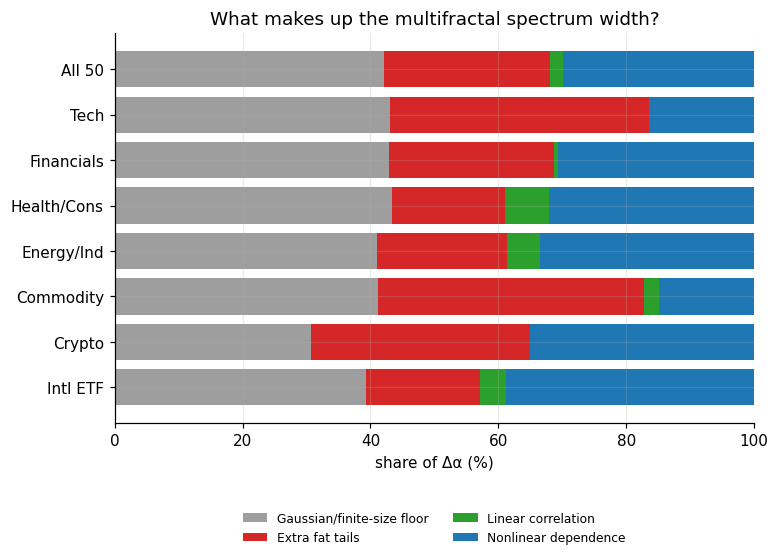

In [31]:
# ═════════ §9a  FOUR-WAY DECOMPOSITION OF Δα (adds the Gaussian / finite-size floor) ═════════
COMP = {
    "Gaussian/finite-size floor": lambda d: d["phase_mean"],
    "Extra fat tails":            lambda d: d["shuffle_mean"] - d["phase_mean"],
    "Linear correlation":         lambda d: d["iaaft_mean"] - d["shuffle_mean"],
    "Nonlinear dependence":       lambda d: d["delta_alpha"] - d["iaaft_mean"],
}
comp = pd.DataFrame({k: f(res) for k, f in COMP.items()}); comp["group"] = res["group"]

def agg_share(df):                      # aggregate share in %, one value per component
    return 100 * df[list(COMP)].sum() / df[list(COMP)].sum().sum()

rb = rng_for("decomp_boot"); B = 2000
boot = np.array([agg_share(comp.iloc[rb.integers(0, len(comp), len(comp))]).values for _ in range(B)])
dec = pd.DataFrame({"aggregate_%": agg_share(comp),
                    "ci_lo": np.percentile(boot, 2.5, axis=0), "ci_hi": np.percentile(boot, 97.5, axis=0),
                    "median_asset_%": (100 * comp[list(COMP)].div(res["delta_alpha"], axis=0)).median()})
print("Four-way decomposition of Δα (aggregate over 50 assets; 95% bootstrap CI over assets):")
print(dec.round(1).to_string()); savetable(dec, "decomposition_four_way.csv")

by_g = comp.groupby("group").apply(agg_share); print("\nBy asset class (aggregate %):"); print(by_g.round(1).to_string())
savetable(by_g, "decomposition_by_class.csv")

# ── Figure: stacked 100% bars (negative linear shares set to 0, then renormalised) ──
fig, ax = plt.subplots(figsize=(7.5, 4.6)); cols = ["#9e9e9e", "#d62728", "#2ca02c", "#1f77b4"]
tbl = pd.concat([dec["aggregate_%"].rename("All 50").to_frame().T, by_g.loc[GROUP_ORDER]])
tbl = tbl.clip(lower=0)
tbl = 100 * tbl.div(tbl.sum(axis=1), axis=0)
left = np.zeros(len(tbl))
for c, col in zip(COMP, cols):
    ax.barh(tbl.index, tbl[c].values, left=left, color=col, label=c)
    left = left + tbl[c].values
ax.set_xlim(0, 100); ax.invert_yaxis(); ax.set_xlabel("share of Δα (%)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.2), ncol=2, frameon=False)
ax.set_title("What makes up the multifractal spectrum width?"); savefig(fig, "fig6_decomposition.png")

[ex-COVID Δα] 1.9 s
Dropping 2020-02-19 → 2020-06-30 (days removed, series concatenated):
  mean Δα 0.548 → 0.445  (mean change -0.103; 40/50 assets fall)
  rank correlation full vs ex-COVID: Spearman ρ = 0.39
  by class (mean Δα):
            full  ex_covid
group                     
Commodity  0.569     0.481
Crypto     0.590     0.549
Equity     0.536     0.436
Intl ETF   0.615     0.454

Defensive names (Δα full → ex-COVID):
       full  ex_covid  change
KO    0.824     0.604  -0.220
PEP   0.784     0.510  -0.274
JNJ   0.753     0.596  -0.157
PG    0.558     0.381  -0.177
WMT   0.534     0.558   0.024
COST  0.509     0.518   0.010
MRK   0.419     0.370  -0.049
ABBV  0.551     0.489  -0.062
PFE   0.581     0.503  -0.078
UNH   0.448     0.467   0.019

Top-8 by Δα, full:  ['KO', 'PEP', 'JNJ', 'BA', 'EWU', 'LMT', 'EWG', 'CL=F']
Top-8 by Δα, ex-COVID: ['KO', 'JNJ', 'UPS', 'RTX', 'WMT', 'INTC', 'ETH-USD', 'BTC-USD']


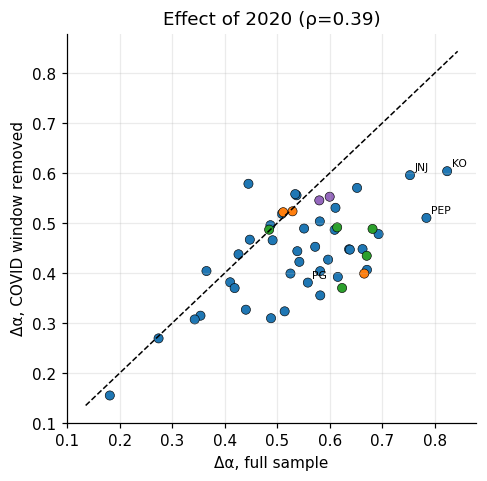

In [12]:
# ═════════ §9b  EX-COVID CHECK: is the high Δα of low-vol defensive names a 2020 effect? ═════════
EXCL = ("2020-02-19", "2020-06-30")      # S&P peak → end of the volatility spike (edit if you prefer another window)
def drop_window(r, a, b): return r[(r.index < pd.Timestamp(a)) | (r.index > pd.Timestamp(b))]

with timed("ex-COVID Δα"):
    exc = pd.Series({t: da_of(drop_window(returns_A[t], *EXCL).values)[0] for t in TICKERS_A})
cmp_ = pd.DataFrame({"full": res["delta_alpha"], "ex_covid": exc, "group": res["group"]}); cmp_["change"] = cmp_.ex_covid - cmp_.full
rho_ec = stats.spearmanr(cmp_.full, cmp_.ex_covid, nan_policy="omit")[0]
print(f"Dropping {EXCL[0]} → {EXCL[1]} (days removed, series concatenated):")
print(f"  mean Δα {cmp_.full.mean():.3f} → {cmp_.ex_covid.mean():.3f}  (mean change {cmp_.change.mean():+.3f}; {int((cmp_.change<0).sum())}/50 assets fall)")
print(f"  rank correlation full vs ex-COVID: Spearman ρ = {rho_ec:.2f}")
print("  by class (mean Δα):"); print(cmp_.groupby("group")[["full", "ex_covid"]].mean().round(3).to_string())
defensive = ["KO", "PEP", "JNJ", "PG", "WMT", "COST", "MRK", "ABBV", "PFE", "UNH"]
print("\nDefensive names (Δα full → ex-COVID):"); print(cmp_.loc[defensive, ["full", "ex_covid", "change"]].round(3).to_string())
print("\nTop-8 by Δα, full: ", cmp_.full.nlargest(8).index.tolist()); print("Top-8 by Δα, ex-COVID:", cmp_.ex_covid.nlargest(8).index.tolist())
savetable(cmp_, "delta_alpha_ex_covid.csv")

fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.scatter(cmp_.full, cmp_.ex_covid, c=[CLASS_COLORS[g] for g in cmp_.group], edgecolor="k", lw=.4)
for t in defensive[:4]: ax.annotate(t, (cmp_.full[t], cmp_.ex_covid[t]), fontsize=7, xytext=(3, 3), textcoords="offset points")
lim = [min(cmp_.full.min(), cmp_.ex_covid.min()) - .02, max(cmp_.full.max(), cmp_.ex_covid.max()) + .02]
ax.plot(lim, lim, "k--", lw=1); ax.set_xlabel("Δα, full sample"); ax.set_ylabel("Δα, COVID window removed"); ax.set_title(f"Effect of 2020 (ρ={rho_ec:.2f})")
savefig(fig, "fig7_ex_covid.png")

[ex-COVID surrogates] 668.4 s
Decomposition of Δα — full sample vs COVID window (2020-02-19 → 2020-06-30) removed:
                           full sample                ex-COVID            
                           aggregate_% ci_lo ci_hi aggregate_% ci_lo ci_hi
Gaussian/finite-size floor        42.1  40.4  44.2        50.5  48.0  53.0
Extra fat tails                   26.0  22.4  30.1        26.2  21.9  30.7
Linear correlation                 2.0   0.2   3.7         0.4  -1.8   2.5
Nonlinear dependence              29.9  25.4  33.6        23.0  18.7  26.7

mean Δα: 0.548 (full) → 0.445 (ex-COVID)
BH q<0.05, temporal dependence   : full 36/50  →  ex-COVID 14/50
BH q<0.05, nonlinear dependence  : full 35/50  →  ex-COVID 15/50
BH q<0.05, non-Gaussian          : full 49/50  →  ex-COVID 48/50


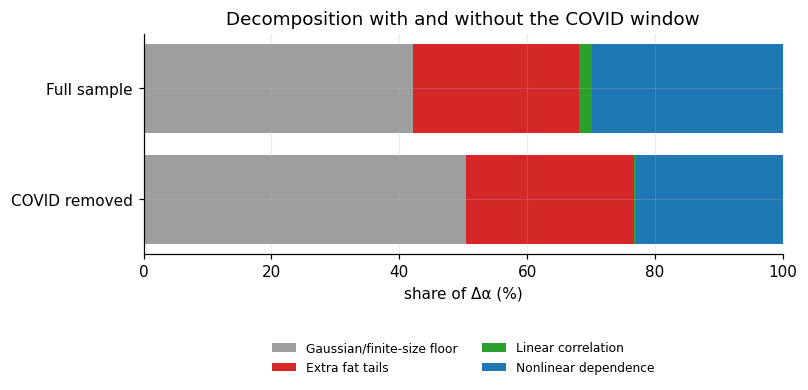

In [13]:
# ═════════ §9d  EX-COVID SURROGATE DECOMPOSITION (does the fat-tail share survive removing 2020?) ═════════
with timed("ex-COVID surrogates"):
    raw_x = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(
        delayed(surrogate_task)(t, drop_window(returns_A[t], *EXCL).values, CFG["N_SURR"], CFG["IAAFT_ITERS"], CFG)
        for t in TICKERS_A)
res_x = pd.DataFrame(raw_x).set_index("ticker").loc[TICKERS_A]; res_x["group"] = [GROUP[t] for t in res_x.index]
for k in ("shuffle", "iaaft", "phase"):
    res_x[f"q_{k}"] = false_discovery_control(res_x[f"p_{k}"].values, method="bh")
savetable(res_x, "delta_alpha_surrogates_ex_covid.csv")

comp_x = pd.DataFrame({k: f(res_x) for k, f in COMP.items()}); comp_x["group"] = res_x["group"]
rb = rng_for("decomp_boot_ex"); boot_x = np.array([agg_share(comp_x.iloc[rb.integers(0, len(comp_x), len(comp_x))]).values for _ in range(B)])
dec_x = pd.DataFrame({"aggregate_%": agg_share(comp_x),
                      "ci_lo": np.percentile(boot_x, 2.5, axis=0), "ci_hi": np.percentile(boot_x, 97.5, axis=0)})
both = pd.concat({"full sample": dec[["aggregate_%", "ci_lo", "ci_hi"]], "ex-COVID": dec_x}, axis=1)
print(f"Decomposition of Δα — full sample vs COVID window ({EXCL[0]} → {EXCL[1]}) removed:"); print(both.round(1).to_string())
savetable(both, "decomposition_full_vs_ex_covid.csv")

n = len(res_x)
print(f"\nmean Δα: {res.delta_alpha.mean():.3f} (full) → {res_x.delta_alpha.mean():.3f} (ex-COVID)")
for k, lab in (("shuffle", "temporal dependence"), ("iaaft", "nonlinear dependence"), ("phase", "non-Gaussian")):
    print(f"BH q<0.05, {lab:22s}: full {(res[f'q_{k}']<.05).sum():>2d}/{n}  →  ex-COVID {(res_x[f'q_{k}']<.05).sum():>2d}/{n}")

fig, ax = plt.subplots(figsize=(7.5, 2.6)); cols = ["#9e9e9e", "#d62728", "#2ca02c", "#1f77b4"]
t2 = pd.DataFrame({"Full sample": dec["aggregate_%"], "COVID removed": dec_x["aggregate_%"]}).T.clip(lower=0)
t2 = 100 * t2.div(t2.sum(axis=1), axis=0); left = np.zeros(2)
for c, col in zip(COMP, cols):
    ax.barh(t2.index, t2[c].values, left=left, color=col, label=c); left = left + t2[c].values
ax.set_xlim(0, 100); ax.invert_yaxis(); ax.set_xlabel("share of Δα (%)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.35), ncol=2, frameon=False)
ax.set_title("Decomposition with and without the COVID window"); savefig(fig, "fig9_decomposition_ex_covid.png")

[window sensitivity] 15.5 s
Δα vs 60d mean pairwise correlation, by window length:
        n_windows  rho_raw  p_raw  rho_vol_controlled  p_vol_controlled
window                                                                 
750           256    0.094  0.750               0.287             0.554
1000          243   -0.118  0.875               0.119             0.892
1500          218   -0.277  0.150              -0.249             0.765

Δα before each peak vs maximum during the episode:
 window   episode  delta_alpha_before  max_during  change date_of_max
    750       GFC               0.285       0.414   0.129  2008-11-03
    750     COVID               0.526       0.752   0.226  2020-04-15
    750 2022 bear               0.513       0.523   0.010  2022-02-09
   1000       GFC               0.301       0.681   0.379  2008-10-20
   1000     COVID               0.561       0.811   0.250  2020-03-31
   1000 2022 bear               0.525       0.572   0.047  2022-08-17
   1500     COV

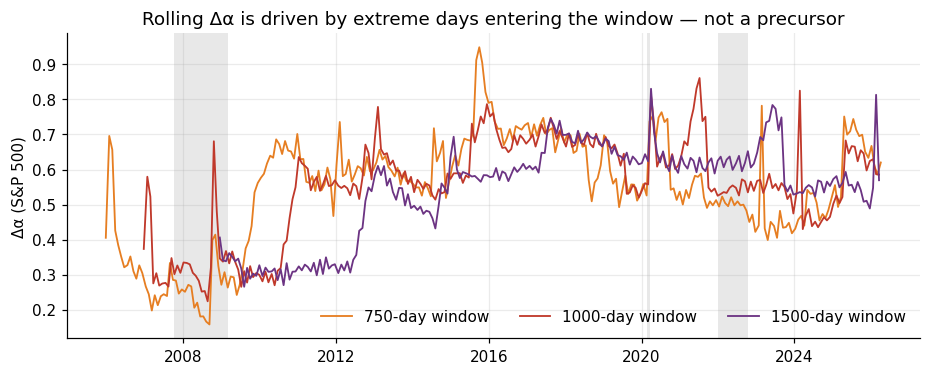

In [14]:
# ═════════ §9c  ROLLING-WINDOW SENSITIVITY (750 / 1000 / 1500 days) + episode table ═════════
WINDOWS = [750, 1000, 1500]
def rolling_da(x, dates, window, step):
    out = {}
    for end in range(window, len(x) + 1, step):
        out[dates[end - 1]] = da_of(x[end - window:end], q=CFG["ROLL_Q"], smin=CFG["ROLL_SCALE_MIN"],
                                    smax=CFG["ROLL_SCALE_MAX"], ns=CFG["ROLL_N_SCALES"])[0]
    return pd.Series(out)

rows, series = [], {}
with timed("window sensitivity"):
    for Wn in WINDOWS:
        s = rolling_da(sp.values, sp.index, Wn, CFG["ROLL_STEP"]); series[Wn] = s
        d = pd.DataFrame({"da": s, "corr": corr60, "vol": vol60}).dropna()
        rho_r, p_r = circ_shift_test(d.da.values, d["corr"].values, CFG["N_PERM"], rng_for(f"w{Wn}_raw"))
        pa_, pc_ = _resid(_rk(d.da.values), _rk(d.vol.values)), _resid(_rk(d["corr"].values), _rk(d.vol.values))
        rho_p = np.corrcoef(pa_, pc_)[0, 1]; lo = len(pa_) // 10
        ks = rng_for(f"w{Wn}_par").integers(lo, len(pa_) - lo, CFG["N_PERM"])
        p_p = (np.sum(np.abs([np.corrcoef(pa_, np.roll(pc_, k))[0, 1] for k in ks]) >= abs(rho_p)) + 1) / (CFG["N_PERM"] + 1)
        rows.append(dict(window=Wn, n_windows=len(d), rho_raw=rho_r, p_raw=p_r, rho_vol_controlled=rho_p, p_vol_controlled=p_p))
sens = pd.DataFrame(rows).set_index("window"); print("Δα vs 60d mean pairwise correlation, by window length:"); print(sens.round(3).to_string())
savetable(sens, "rolling_window_sensitivity.csv")

# episode table: Δα just BEFORE each peak vs the highest Δα within the episode (+60 days)
EPI = [("2007-10-09", "2009-03-09", "GFC"), ("2020-02-19", "2020-03-23", "COVID"), ("2022-01-03", "2022-10-12", "2022 bear")]
ep = []
for Wn, s in series.items():
    for a, b, lab in EPI:
        pre = s[:pd.Timestamp(a)]; inside = s[pd.Timestamp(a):pd.Timestamp(b) + pd.Timedelta(days=60)]
        if len(pre) and len(inside):
            ep.append(dict(window=Wn, episode=lab, delta_alpha_before=pre.iloc[-1], max_during=inside.max(),
                           change=inside.max() - pre.iloc[-1], date_of_max=inside.idxmax().date()))
ep = pd.DataFrame(ep); print("\nΔα before each peak vs maximum during the episode:"); print(ep.round(3).to_string(index=False))
savetable(ep, "rolling_episode_table.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 3.6))
for Wn, c in zip(WINDOWS, ["#e67e22", "#c0392b", "#6c3483"]): ax.plot(series[Wn], c=c, lw=1.2, label=f"{Wn}-day window")
for a, b, lab in EPI: ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="#999", alpha=.22, lw=0)
ax.set_ylabel("Δα (S&P 500)"); ax.legend(frameon=False, ncol=3); ax.set_title("Rolling Δα is driven by extreme days entering the window — not a precursor")
savefig(fig, "fig8_window_sensitivity.png")

In [15]:
extra = dict(
    decomposition_aggregate_pct=dec["aggregate_%"].round(2).to_dict(),
    decomposition_ci=dec[["ci_lo", "ci_hi"]].round(2).to_dict("index"),
    ex_covid_rank_rho=float(rho_ec), ex_covid_mean_change=float(cmp_.change.mean()),
    window_sensitivity=sens.round(4).to_dict("index"),
)
p = BASE / "paper_numbers.json"; d = json.loads(p.read_text()); d.update(extra)
p.write_text(json.dumps(d, indent=1, default=str)); print("paper_numbers.json updated")

paper_numbers.json updated


[placebo windows] 60.2 s
150 placebo windows of 132 calendar days (none overlapping 2020-02-19 → 2020-06-30)
  mean Δα change, placebo windows: +0.001  (5th–95th pct: -0.007 … +0.009)
  mean Δα change, COVID window  : -0.103   → empirical one-sided p = 0.007
  assets whose Δα falls: COVID 40/50  vs placebo mean 24.2/50

By asset class:
            n  covid_change  placebo_mean  placebo_p05  empirical_p
group                                                              
Commodity   3        -0.087        -0.003       -0.035        0.007
Crypto      2        -0.041         0.002       -0.022        0.026
Equity     40        -0.100         0.002       -0.008        0.007
Intl ETF    5        -0.161        -0.004       -0.024        0.007


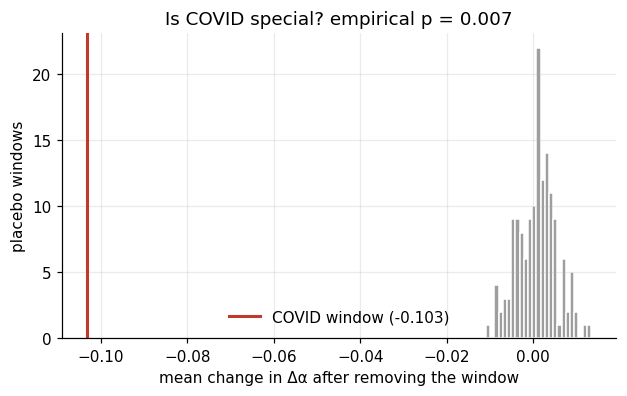

In [16]:
# ═════════ §9e  PLACEBO: how unusual is the COVID window's effect on Δα? ═════════
# Remove K random windows of the SAME calendar length (never overlapping the COVID window), recompute Δα,
# and compare the mean fall in Δα with the fall caused by removing COVID (cmp_.change.mean() from §9b).
K = int(os.environ.get("FLR_N_PLACEBO", 150))
span = pd.Timestamp(EXCL[1]) - pd.Timestamp(EXCL[0])
cand = pd.date_range(pd.Timestamp(CFG["START_A"]) + pd.Timedelta(days=30),
                     pd.Timestamp(CFG["END_A"]) - span - pd.Timedelta(days=30), freq="D")
ok = cand[(cand + span < pd.Timestamp(EXCL[0])) | (cand > pd.Timestamp(EXCL[1]))]
starts = pd.DatetimeIndex(rng_for("placebo_windows").choice(ok, K, replace=False)).sort_values()

def placebo_task(ticker, r, starts, span, cfg):
    q, smin, smax, ns, po, ov = (cfg[k] for k in ("Q_VALS", "SCALE_MIN", "SCALE_MAX", "N_SCALES", "POLY_ORD", "OVERLAP"))
    vals, idx = r.values, r.index; out = np.full(len(starts), np.nan)
    for i, s in enumerate(starts):
        keep = (idx < s) | (idx > s + span)
        _, _, hq = mfdfa_fast(vals[keep], q, smin, smax, ns, po, ov); out[i] = delta_alpha(q, hq)
    return ticker, out

with timed("placebo windows"):
    raw_p = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(
        delayed(placebo_task)(t, returns_A[t], starts, span, CFG) for t in TICKERS_A)
P = pd.DataFrame({t: v for t, v in raw_p}, index=starts)[TICKERS_A]            # K × 50 matrix of Δα
chg = P.sub(res["delta_alpha"], axis=1)                                        # change vs full-sample Δα

covid_mean = float(cmp_.change.mean()); plc_mean = chg.mean(axis=1)            # mean change across assets, per placebo
p_emp = (np.sum(plc_mean <= covid_mean) + 1) / (K + 1)
print(f"{K} placebo windows of {span.days} calendar days (none overlapping {EXCL[0]} → {EXCL[1]})")
print(f"  mean Δα change, placebo windows: {plc_mean.mean():+.3f}  (5th–95th pct: {plc_mean.quantile(.05):+.3f} … {plc_mean.quantile(.95):+.3f})")
print(f"  mean Δα change, COVID window  : {covid_mean:+.3f}   → empirical one-sided p = {p_emp:.3f}")
print(f"  assets whose Δα falls: COVID {int((cmp_.change<0).sum())}/50  vs placebo mean {(chg<0).sum(axis=1).mean():.1f}/50")
rows = []
for g in sorted(set(GROUP.values())):
    cols = [t for t in TICKERS_A if GROUP[t] == g]
    rows.append(dict(group=g, n=len(cols), covid_change=cmp_.loc[cols, "change"].mean(),
                     placebo_mean=chg[cols].mean(axis=1).mean(), placebo_p05=chg[cols].mean(axis=1).quantile(.05),
                     empirical_p=(np.sum(chg[cols].mean(axis=1) <= cmp_.loc[cols, "change"].mean()) + 1) / (K + 1)))
by_grp = pd.DataFrame(rows).set_index("group"); print("\nBy asset class:"); print(by_grp.round(3).to_string())
savetable(by_grp, "placebo_by_class.csv"); savetable(chg, "placebo_delta_alpha_change.csv")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(plc_mean, bins=25, color="#9e9e9e", edgecolor="white"); ax.axvline(covid_mean, color="#c0392b", lw=2, label=f"COVID window ({covid_mean:+.3f})")
ax.set_xlabel("mean change in Δα after removing the window"); ax.set_ylabel("placebo windows"); ax.legend(frameon=False)
ax.set_title(f"Is COVID special? empirical p = {p_emp:.3f}"); savefig(fig, "fig10_placebo_windows.png")

In [17]:
# ═════════ §10a  EXTENDED SAMPLE FROM 2008: which assets actually existed? ═════════
START_D, END_D = "2008-01-01", CFG["END_A"]
ELIG_BY = pd.Timestamp("2008-01-31")           # asset must have data by this date to count as existing at the start

def try_close(t):
    try: return get_close(t, START_D, END_D)
    except Exception as e:
        print(f"  {t}: no data / download failed ({str(e)[:60]})"); return pd.Series(dtype=float, name=t)

with timed("extended data (2008→)"):
    prices_D = pd.concat([try_close(t) for t in TICKERS_A], axis=1, sort=False)

returns_D, rows = {}, []
for t in TICKERS_A:
    p = prices_D[t].dropna() if t in prices_D else pd.Series(dtype=float)
    p = p[p > 0]
    first = p.index[0] if len(p) else pd.NaT
    ok = len(p) > 0 and first <= ELIG_BY
    rows.append(dict(ticker=t, group=GROUP[t], first_price_date=first.date() if len(p) else None, n_prices=len(p),
                     eligible=ok, reason="" if ok else ("no data" if not len(p) else f"first data {first.date()} (after {ELIG_BY.date()})")))
    if ok: returns_D[t] = np.log(p).diff().dropna()
elig = pd.DataFrame(rows).set_index("ticker"); ELIG_D = list(returns_D)
savetable(elig, "extended_sample_eligibility.csv")
print(f"Eligible assets: {len(ELIG_D)} of {len(TICKERS_A)}  (data from {START_D}, existing by {ELIG_BY.date()})")
print(elig[elig.eligible].groupby("group").size().to_string())
print("\nEXCLUDED (not trading / no data by Jan 2008):"); print(elig[~elig.eligible][["group", "first_price_date", "reason"]].to_string())
print("\nObservations per eligible asset: min", min(len(r) for r in returns_D.values()), "max", max(len(r) for r in returns_D.values()))

[extended data (2008→)] 26.1 s
Eligible assets: 44 of 50  (data from 2008-01-01, existing by 2008-01-31)
group
Commodity     3
Equity       36
Intl ETF      5

EXCLUDED (not trading / no data by Jan 2008):
          group first_price_date                                    reason
ticker                                                                    
META     Equity       2012-05-18  first data 2012-05-18 (after 2008-01-31)
TSLA     Equity       2010-06-29  first data 2010-06-29 (after 2008-01-31)
V        Equity       2008-03-19  first data 2008-03-19 (after 2008-01-31)
ABBV     Equity       2013-01-02  first data 2013-01-02 (after 2008-01-31)
BTC-USD  Crypto       2014-09-17  first data 2014-09-17 (after 2008-01-31)
ETH-USD  Crypto       2017-11-09  first data 2017-11-09 (after 2008-01-31)

Observations per eligible asset: min 4595 max 4596


[Δα by scenario] 6.7 s
Δα on the 44 assets existing in Jan 2008 (sample 2008-01-01 → 2026-04-11):
          mean_delta_alpha  mean_change  pct_change  n_assets_fall
full                 0.496        0.000       0.000            0.0
ex-GFC               0.549        0.054      10.867           13.0
ex-COVID             0.451       -0.045      -9.064           32.0
ex-both              0.461       -0.034      -6.954           26.0
[placebo windows (extended)] 107.8 s

Placebo test (150 random same-length windows each):
                                 length_days  crisis_change  placebo_mean  placebo_p05  placebo_min  empirical_p assets_falling placebo_assets_falling
window                                                                                                                                                
GFC (2008-09-01 → 2009-06-30)            302          0.054         0.002       -0.006       -0.010        1.000          13/44                19.6/44
COVID (2020-02-19 → 2020

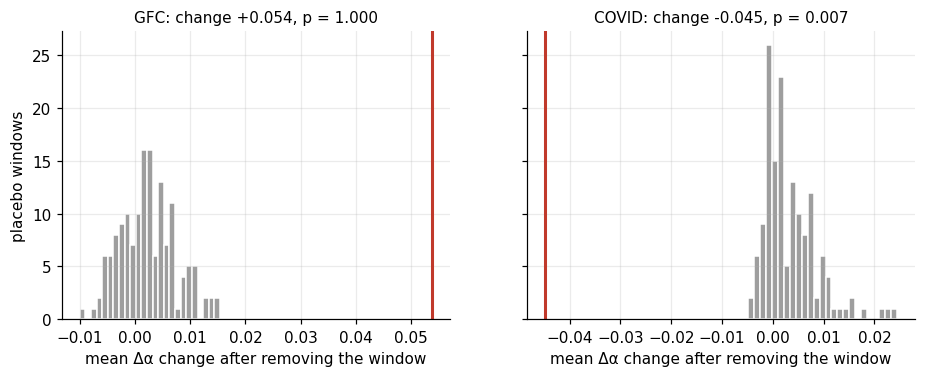

In [18]:
# ═════════ §10b  GFC vs COVID: how much of Δα does each crisis window carry? (with placebo windows) ═════════
EPISODES_D = {"GFC": ("2008-09-01", "2009-06-30"), "COVID": EXCL}
def remove_windows(r, wins):
    keep = np.ones(len(r), bool)
    for a, b in wins: keep &= ~((r.index >= pd.Timestamp(a)) & (r.index <= pd.Timestamp(b)))
    return r[keep]
SCEN = {"full": [], "ex-GFC": [EPISODES_D["GFC"]], "ex-COVID": [EPISODES_D["COVID"]], "ex-both": list(EPISODES_D.values())}

with timed("Δα by scenario"):
    dA = pd.DataFrame({s: {t: da_of(remove_windows(returns_D[t], w).values)[0] for t in ELIG_D} for s, w in SCEN.items()})
dA["group"] = [GROUP[t] for t in dA.index]; savetable(dA, "extended_delta_alpha_by_scenario.csv")
summ = pd.DataFrame({s: dict(mean_delta_alpha=dA[s].mean(), mean_change=(dA[s] - dA["full"]).mean(),
                             pct_change=100 * (dA[s] - dA["full"]).mean() / dA["full"].mean(),
                             n_assets_fall=int((dA[s] < dA["full"]).sum())) for s in SCEN}).T
print(f"Δα on the {len(ELIG_D)} assets existing in Jan 2008 (sample {START_D} → {END_D}):"); print(summ.round(3).to_string())
savetable(summ, "extended_scenario_summary.csv")

# ---- placebo: K random windows of each crisis window's length, not overlapping EITHER crisis window ----
K = int(os.environ.get("FLR_N_PLACEBO", 150))
def placebo_task(ticker, r, starts, span, cfg):
    q, smin, smax, ns, po, ov = (cfg[k] for k in ("Q_VALS", "SCALE_MIN", "SCALE_MAX", "N_SCALES", "POLY_ORD", "OVERLAP"))
    vals, idx = r.values, r.index; out = np.full(len(starts), np.nan)
    for i, s in enumerate(starts):
        keep = (idx < s) | (idx > s + span)
        _, _, hq = mfdfa_fast(vals[keep], q, smin, smax, ns, po, ov); out[i] = delta_alpha(q, hq)
    return ticker, out

plc_rows, plc_store = [], {}
with timed("placebo windows (extended)"):
    for name, (a, b) in EPISODES_D.items():
        span = pd.Timestamp(b) - pd.Timestamp(a)
        cand = pd.date_range(pd.Timestamp(START_D) + pd.Timedelta(days=30), pd.Timestamp(END_D) - span - pd.Timedelta(days=30), freq="D")
        free = np.ones(len(cand), bool)
        for (x, y) in EPISODES_D.values(): free &= (cand + span < pd.Timestamp(x)) | (cand > pd.Timestamp(y))
        starts = pd.DatetimeIndex(rng_for(f"placebo_ext_{name}").choice(cand[free], K, replace=False)).sort_values()
        raw_p = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(delayed(placebo_task)(t, returns_D[t], starts, span, CFG) for t in ELIG_D)
        chg = pd.DataFrame({t: v for t, v in raw_p}, index=starts)[ELIG_D].sub(dA["full"], axis=1)
        plc_mean = chg.mean(axis=1); real = float((dA[f"ex-{name}"] - dA["full"]).mean()); plc_store[name] = (plc_mean, real)
        plc_rows.append(dict(window=f"{name} ({a} → {b})", length_days=span.days, crisis_change=real,
                             placebo_mean=plc_mean.mean(), placebo_p05=plc_mean.quantile(.05), placebo_min=plc_mean.min(),
                             empirical_p=(np.sum(plc_mean <= real) + 1) / (K + 1),
                             assets_falling=f"{int((dA[f'ex-{name}'] < dA['full']).sum())}/{len(ELIG_D)}",
                             placebo_assets_falling=f"{(chg < 0).sum(axis=1).mean():.1f}/{len(ELIG_D)}"))
plc = pd.DataFrame(plc_rows).set_index("window"); print(f"\nPlacebo test ({K} random same-length windows each):"); print(plc.round(3).to_string())
savetable(plc, "extended_placebo_summary.csv")
by_g = pd.DataFrame({s: (dA[s] - dA["full"]).groupby(dA["group"]).mean() for s in ("ex-GFC", "ex-COVID", "ex-both")})
print("\nMean change in Δα by asset class:"); print(by_g.round(3).to_string()); savetable(by_g, "extended_change_by_class.csv")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (name, (pm, real)) in zip(axs, plc_store.items()):
    ax.hist(pm, bins=25, color="#9e9e9e", edgecolor="white"); ax.axvline(real, color="#c0392b", lw=2)
    ax.set_title(f"{name}: change {real:+.3f}, p = {plc.iloc[list(plc_store).index(name)].empirical_p:.3f}", fontsize=10); ax.set_xlabel("mean Δα change after removing the window")
axs[0].set_ylabel("placebo windows"); savefig(fig, "fig11_placebo_gfc_covid.png")

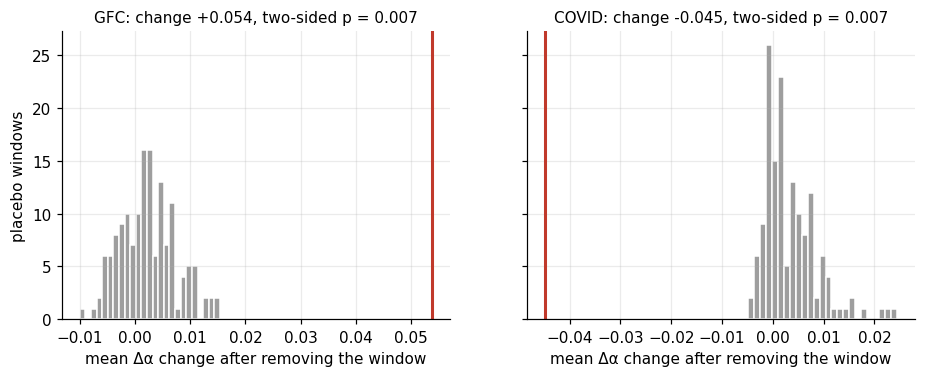

In [22]:
# Redraw Fig. 11 with two-sided empirical p-values in the panel titles
def two_sided_p(plc_mean, real, K):
    c = plc_mean.mean()
    return (np.sum(np.abs(plc_mean - c) >= abs(real - c)) + 1) / (K + 1)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (name, (pm, real)) in zip(axs, plc_store.items()):
    p2 = two_sided_p(pm, real, K)
    ax.hist(pm, bins=25, color="#9e9e9e", edgecolor="white")
    ax.axvline(real, color="#c0392b", lw=2)
    ax.set_title(f"{name}: change {real:+.3f}, two-sided p = {p2:.3f}", fontsize=10)
    ax.set_xlabel("mean Δα change after removing the window")
axs[0].set_ylabel("placebo windows")
savefig(fig, "fig11_placebo_gfc_covid.png")

In [19]:
# ═════════ §10c  FOUR-WAY DECOMPOSITION ON THE 2008-START SAMPLE, BY SCENARIO (slow) ═════════
DECOMP_SCEN = ["full", "ex-GFC", "ex-COVID"]
out, counts = {}, {}
for s in DECOMP_SCEN:
    with timed(f"surrogates {s}"):
        raw = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(
            delayed(surrogate_task)(t, remove_windows(returns_D[t], SCEN[s]).values, CFG["N_SURR"], CFG["IAAFT_ITERS"], CFG) for t in ELIG_D)
    rs = pd.DataFrame(raw).set_index("ticker").loc[ELIG_D]; rs["group"] = [GROUP[t] for t in rs.index]
    for k in ("shuffle", "iaaft", "phase"): rs[f"q_{k}"] = false_discovery_control(rs[f"p_{k}"].values, method="bh")
    savetable(rs, f"extended_surrogates_{s.replace('-', '_')}.csv")
    cm = pd.DataFrame({k: f(rs) for k, f in COMP.items()}); cm["group"] = rs["group"]
    rb = rng_for(f"decomp_boot_ext_{s}"); bt = np.array([agg_share(cm.iloc[rb.integers(0, len(cm), len(cm))]).values for _ in range(2000)])
    agg = agg_share(cm); mean_da = rs.delta_alpha.mean()
    out[s] = pd.DataFrame({"share_%": agg, "ci_lo": np.percentile(bt, 2.5, axis=0), "ci_hi": np.percentile(bt, 97.5, axis=0), "abs_delta_alpha": agg / 100 * mean_da})
    counts[s] = dict(mean_delta_alpha=mean_da, n_assets=len(rs), sig_temporal=int((rs.q_shuffle < .05).sum()),
                     sig_nonlinear=int((rs.q_iaaft < .05).sum()), sig_non_gaussian=int((rs.q_phase < .05).sum()))
dec_ext = pd.concat(out, axis=1); print("Four-way decomposition (aggregate shares, 95% bootstrap CI over assets; absolute = share × mean Δα):")
print(dec_ext.round(3).to_string()); savetable(dec_ext, "extended_decomposition_by_scenario.csv")
cnt = pd.DataFrame(counts).T; print("\nAssets passing BH q<0.05:"); print(cnt.round(3).to_string()); savetable(cnt, "extended_test_counts_by_scenario.csv")

[surrogates full] 1058.6 s
[surrogates ex-GFC] 694.0 s
[surrogates ex-COVID] 746.2 s
Four-way decomposition (aggregate shares, 95% bootstrap CI over assets; absolute = share × mean Δα):
                              full                                  ex-GFC                                 ex-COVID                                
                           share_%   ci_lo   ci_hi abs_delta_alpha share_%   ci_lo   ci_hi abs_delta_alpha  share_%   ci_lo   ci_hi abs_delta_alpha
Gaussian/finite-size floor  40.514  38.349  42.898           0.201  42.475  40.453  44.687           0.233   42.952  40.704  45.333           0.194
Extra fat tails             39.052  34.222  44.295           0.194  25.002  21.175  29.436           0.137   41.255  35.725  47.309           0.186
Linear correlation          -2.462  -4.447  -0.663          -0.012   3.128   1.564   4.586           0.017   -4.616  -7.223  -2.156          -0.021
Nonlinear dependence        22.896  18.183  27.471           0.113  29.395

,mean_delta_alpha,n_assets,sig_temporal,sig_nonlinear,sig_non_gaussian
full,0.495545,44.0,12.0,17.0,44.0
ex-GFC,0.549396,44.0,31.0,32.0,44.0
ex-COVID,0.450630,44.0,11.0,7.0,44.0


In [20]:
for name, (pm, real) in plc_store.items():
    p2 = (np.sum(np.abs(pm - pm.mean()) >= abs(real - pm.mean())) + 1) / (len(pm) + 1)
    print(f"{name}: change {real:+.3f}, placebo 5–95% [{pm.quantile(.05):+.3f}, {pm.quantile(.95):+.3f}], two-sided p = {p2:.3f}")

GFC: change +0.054, placebo 5–95% [-0.006, +0.011], two-sided p = 0.007
COVID: change -0.045, placebo 5–95% [-0.003, +0.012], two-sided p = 0.007


[block simulation] 20.9 s
Δα change vs no block, by block length (paired, iid-t baseline):
multiplier      3      6
block_days              
0           0.000  0.000
10          0.021  0.103
20          0.048  0.185
40          0.075  0.230
60          0.097  0.234
90          0.113  0.217
133         0.109  0.178
200         0.089  0.129
300         0.067  0.089
450         0.047  0.057

Two-episode interaction (mean Δα):
none                          0.352
GFC-like only (302d, ×3)      0.411
COVID-like only (132d, ×6)    0.541
both                          0.518
                       effect of adding GFC-like block  effect of adding COVID-like block
other episode absent                             0.059                              0.189
other episode present                           -0.023                              0.107


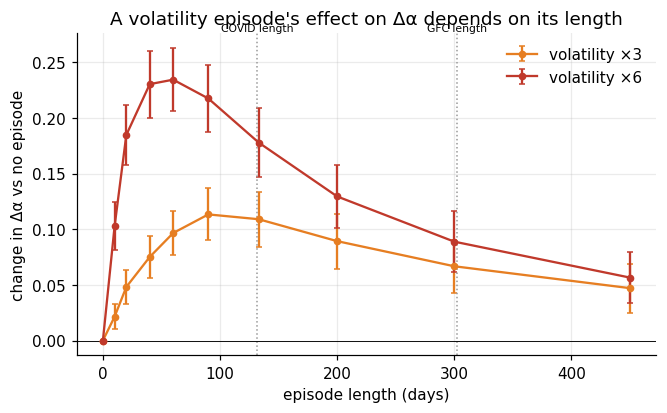

In [21]:
# ═════════ §11  SIMULATION: does the SHAPE of a volatility episode set the sign of its effect on Δα? ═════════
# Baseline: iid Student-t(4) returns, sd 1% (no clustering, no episodes). We inject volatility "episodes" (blocks whose returns
# are multiplied by m) and measure Δα with the same MF-DFA settings as the empirical work. Series length = the 2008-start sample.
N_SIM = int(os.environ.get("FLR_N_SIM", 100)); N_OBS = 4600

def sim_blocks(L, m, R, N, cfg, two=None):
    q, smin, smax, ns, po, ov = (cfg[k] for k in ("Q_VALS", "SCALE_MIN", "SCALE_MAX", "N_SCALES", "POLY_ORD", "OVERLAP"))
    rx = np.random.default_rng(np.random.SeedSequence([cfg["SEED"], 101]))      # same base series for every (L, m)  → paired comparison
    rp = np.random.default_rng(np.random.SeedSequence([cfg["SEED"], 202]))      # block position
    out = np.empty(R)
    for i in range(R):
        x = 0.01 * rx.standard_t(4, N) / np.sqrt(2)
        if two is None:
            pos = rp.integers(int(.2 * N), int(.8 * N) - max(L, 1))
            if L > 0: x[pos:pos + L] *= m
        else:                                                                      # two = (gfc_mult, covid_mult)
            if two[0]: x[int(.05 * N):int(.05 * N) + 302] *= two[0]               # GFC-like: 302 days, early
            if two[1]: x[int(.80 * N):int(.80 * N) + 132] *= two[1]               # COVID-like: 132 days, late
        _, _, hq = mfdfa_fast(x, q, smin, smax, ns, po, ov); out[i] = delta_alpha(q, hq)
    return out

LS, MS = [0, 10, 20, 40, 60, 90, 133, 200, 300, 450], [3, 6]
jobs = [(L, m) for m in MS for L in LS]
CASES = {"none": (0, 0), "GFC-like only (302d, ×3)": (3, 0), "COVID-like only (132d, ×6)": (0, 6), "both": (3, 6)}
with timed("block simulation"):
    res_s = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(delayed(sim_blocks)(L, m, N_SIM, N_OBS, CFG) for L, m in jobs)
    res_t = Parallel(n_jobs=CFG["N_JOBS"], backend="loky")(delayed(sim_blocks)(0, 0, N_SIM, N_OBS, CFG, two) for two in CASES.values())

sweep = {}
for (L, m), r in zip(jobs, res_s): sweep[(m, L)] = r
base = sweep[(MS[0], 0)]
rows = [dict(multiplier=m, block_days=L, mean_delta_alpha=r.mean(), change_vs_no_block=(r - base).mean(),
             se=(r - base).std(ddof=1) / np.sqrt(len(r))) for (m, L), r in sweep.items()]
sweep_df = pd.DataFrame(rows); savetable(sweep_df, "simulation_block_length.csv", index=False)
print("Δα change vs no block, by block length (paired, iid-t baseline):")
print(sweep_df.pivot(index="block_days", columns="multiplier", values="change_vs_no_block").round(3).to_string())

d = dict(zip(CASES, res_t)); two_tbl = pd.Series({k: v.mean() for k, v in d.items()}, name="mean_delta_alpha")
n_, g_, c_, b_ = (d[k] for k in CASES)
inter = pd.DataFrame({"effect of adding GFC-like block": [(g_ - n_).mean(), (b_ - c_).mean()],
                      "effect of adding COVID-like block": [(c_ - n_).mean(), (b_ - g_).mean()]}, index=["other episode absent", "other episode present"])
print("\nTwo-episode interaction (mean Δα):"); print(two_tbl.round(3).to_string()); print(inter.round(3).to_string())
savetable(two_tbl.to_frame(), "simulation_two_episodes.csv"); savetable(inter, "simulation_interaction.csv")

fig, ax = plt.subplots(figsize=(6.8, 3.8)); cols = {3: "#e67e22", 6: "#c0392b"}
for m in MS:
    s = sweep_df[sweep_df.multiplier == m]
    ax.errorbar(s.block_days, s.change_vs_no_block, yerr=1.96 * s.se, marker="o", ms=4, color=cols[m], capsize=2, label=f"volatility ×{m}")
for L_, lab in ((132, "COVID length"), (302, "GFC length")): ax.axvline(L_, color="#999", ls=":", lw=1); ax.text(L_, ax.get_ylim()[1], lab, fontsize=7, ha="center", va="bottom")
ax.axhline(0, color="k", lw=.6); ax.set_xlabel("episode length (days)"); ax.set_ylabel("change in Δα vs no episode"); ax.legend(frameon=False)
ax.set_title("A volatility episode's effect on Δα depends on its length"); savefig(fig, "fig12_simulation_block_length.png")